# SWLDA 拒绝策略比较

按功能合并的报告。首先展示最新覆盖范围，其后保留早期实验与复核记录。

各章节的数据范围、阈值版本和历史输出独立，不能合并为同一个实验。重新运行时请重启 kernel，从所需章节的初始化单元开始；人工交互章节按原说明操作。

更新：运行原报告 builder 会直接更新对应章节，保留其他章节的结果。

---

## 主要结果：bigp3bci_swlda_all_studyf

# 完整三Session：SWLDA与epoch拒绝策略

固定纳入F03、F05、F06、F07、F08、F20、F21、F23、F24、F25的SE001–SE003全部Train/CBCol EDF，共90份。每个被试×Session独立训练，Session内按EDF文件名与字符顺序取前2/3完整字符训练，其余验证。文件名顺序作为跨文件采集顺序代理，不推断未知的现实暂停。三策略复用同一划分；不读取最终Test。

A：基础故障与技术检查；B：A＋任一16通道PTP>150µV；C：A＋固定old_candidate_overlap_v1旧候选区间重叠拒绝。C保留原25µV额区幅值及其配套规则，不混用新版主波、恢复区间或局部突出度方案。滤波保持60Hz notch→0.5–30Hz因果滤波，逐EDF连续保留状态。


In [4]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/swlda_all_studyf.json').exists())
OUT=ROOT/'outputs/swlda_all_studyf_v3'
cfg=json.loads((OUT/'config_snapshot.json').read_text())
record=json.loads((OUT/'implementation_record.json').read_text())
models=pd.read_csv(OUT/'model_summary.csv')
pred=pd.read_csv(OUT/'character_predictions.csv')
split=pd.read_csv(OUT/'character_split.csv')
overall=pd.read_csv(OUT/'overall_character_summary.csv')
sessions=pd.read_csv(OUT/'session_character_summary.csv')
ret=pd.read_csv(OUT/'validation_retention.csv')
auc=pd.read_csv(OUT/'validation_auc.csv')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
display(pd.Series(record).to_frame('implementation'))


,implementation
classifier,"SWLDA, project-owned OLS forward/backward step..."
implementation_file,src/bigp3bci_swlda.py
implementation_sha256,03867b6ca5a91c0d5711d82683b3705082ba97dc7d1bf0...
reference,https://www.bci2000.org/mediawiki/index.php/Us...
source_config_sha256,673d89a2bdca40c33dc50eb6c2fc9ad4b19857c2113cad...
split_sha256,c4c400aa6964ee223bb1eb7855cee57aa25a6583b97d70...
feature_count,256
models,90
training_characters,360
validation_characters,180


## 1. 数据覆盖、校准预算与划分

先固定完整字符划分，再筛选epoch。每个Session有3份EDF；拒绝后不会追加字符来补足训练epoch。校准预算按实际采集字符和记录时长统计，跨EDF未知间隔不计作已知时长。观察到的非126次flash字符原样保留，不为符合预期改数量。


In [5]:
manifest=pd.read_csv(ROOT/'outputs/studyf_all_preprocessing/selection_manifest.csv')
coverage=manifest.groupby(['subject_id','session_id']).size().unstack()
display(coverage)
assert coverage.shape==(10,3) and coverage.eq(3).all().all()
display(pd.read_csv(OUT/'character_inventory_and_split.csv'))
display(pd.read_csv(OUT/'calibration_and_retention.csv'))


session_id,SE001,SE002,SE003
subject_id,,,
F_03,3,3,3
F_05,3,3,3
F_06,3,3,3
F_07,3,3,3
F_08,3,3,3
F_20,3,3,3
F_21,3,3,3
F_23,3,3,3
F_24,3,3,3


,subject_id,session_id,set,character_trials,flashes
0,F_03,SE001,train,12,1512
1,F_03,SE001,validation,6,756
2,F_03,SE002,train,12,1512
3,F_03,SE002,validation,6,756
4,F_03,SE003,train,12,1512
5,F_03,SE003,validation,6,756
6,F_05,SE001,train,12,1512
7,F_05,SE001,validation,6,756
8,F_05,SE002,train,12,1512
9,F_05,SE002,validation,6,756


,model_id,policy,subject_id,session_id,site,fit_status,n_selected,training_characters,validation_characters,training_epochs,training_target_epochs,fit_cpu_wall_seconds,acquired_calibration_seconds,training_collected_flashes,validation_collected_flashes,training_kept_epochs,validation_kept_epochs
0,F_03_SE001,A,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.058305,423.125,1512,756,1468,734
1,F_03_SE001,B,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.059480,423.125,1512,756,1468,734
2,F_03_SE001,C,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.062744,423.125,1512,756,1468,734
3,F_03_SE002,A,F_03,SE002,ETSU,converged,53,12,6,1468,164,0.049152,423.125,1512,756,1468,734
4,F_03_SE002,B,F_03,SE002,ETSU,converged,53,12,6,1468,164,0.050924,423.125,1512,756,1468,734
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,F_25_SE002,B,F_25,SE002,ETSU,converged,50,12,6,1468,163,0.044690,423.125,1512,756,1468,734
86,F_25_SE002,C,F_25,SE002,ETSU,converged,53,12,6,1221,125,0.046740,423.125,1512,756,1221,437
87,F_25_SE003,A,F_25,SE003,ETSU,converged,39,12,6,1468,163,0.031637,423.125,1512,756,1468,734
88,F_25_SE003,B,F_25,SE003,ETSU,converged,19,12,6,1458,162,0.017443,423.125,1512,756,1458,726


## 2. 映射与训练／验证边界核验

字符预测使用每次flash实际亮起的36个字符状态通道；StimulusCode不当字符编号。CurrentTarget仅用于真值和映射核验，不输入字符预测。集合边界检查共享原始样本以及训练策略确认是否进入验证期。连续因果滤波可使用历史状态，不使用未来验证样本拟合训练参数。


In [6]:
mapping=pd.read_csv(OUT/'mapping_audit.csv')
leak=pd.read_csv(OUT/'split_leakage_audit.csv')
display(mapping)
display(leak)
assert mapping.target_membership_label_disagreements.eq(0).all()
assert not leak.shared_raw_samples.any()
assert not leak.training_confirmation_enters_validation.any()


,edf_name,subject_id,session_id,n_flashes,n_character_state_channels,target_membership_label_disagreements,source_truth,prediction_mapping,true_ids_observed
0,F_03_SE001_CBCol_Train01.edf,F_03,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[5, 6, 18, 20, 21]"
1,F_03_SE001_CBCol_Train02.edf,F_03,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[3, 4, 5, 9, 22]"
2,F_03_SE001_CBCol_Train03.edf,F_03,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[4, 5, 7, 18]"
3,F_03_SE002_CBCol_Train01.edf,F_03,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 4, 7, 9, 14]"
4,F_03_SE002_CBCol_Train02.edf,F_03,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[4, 5, 15, 18, 19]"
...,...,...,...,...,...,...,...,...,...
85,F_25_SE002_CBCol_Train02.edf,F_25,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[7, 8, 9, 11, 14, 20]"
86,F_25_SE002_CBCol_Train03.edf,F_25,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 2, 3, 11, 16, 21]"
87,F_25_SE003_CBCol_Train01.edf,F_25,SE003,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 3, 11, 20]"
88,F_25_SE003_CBCol_Train02.edf,F_25,SE003,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 2, 7, 12, 15]"


,edf_name,model_id,policy,raw_sample_gap,training_policy_to_first_validation_seconds,shared_raw_samples,training_confirmation_enters_validation,scope,train_edfs,validation_edfs
0,NaN,F_03_SE001,A,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE001_CBCol_Train01.edf;F_03_SE001_CBCol_...,F_03_SE001_CBCol_Train03.edf
1,NaN,F_03_SE001,B,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE001_CBCol_Train01.edf;F_03_SE001_CBCol_...,F_03_SE001_CBCol_Train03.edf
2,NaN,F_03_SE001,C,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE001_CBCol_Train01.edf;F_03_SE001_CBCol_...,F_03_SE001_CBCol_Train03.edf
3,NaN,F_03_SE002,A,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE002_CBCol_Train01.edf;F_03_SE002_CBCol_...,F_03_SE002_CBCol_Train03.edf
4,NaN,F_03_SE002,B,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE002_CBCol_Train01.edf;F_03_SE002_CBCol_...,F_03_SE002_CBCol_Train03.edf
...,...,...,...,...,...,...,...,...,...,...
85,NaN,F_25_SE002,B,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_25_SE002_CBCol_Train01.edf;F_25_SE002_CBCol_...,F_25_SE002_CBCol_Train03.edf
86,NaN,F_25_SE002,C,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_25_SE002_CBCol_Train01.edf;F_25_SE002_CBCol_...,F_25_SE002_CBCol_Train03.edf
87,NaN,F_25_SE003,A,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_25_SE003_CBCol_Train01.edf;F_25_SE003_CBCol_...,F_25_SE003_CBCol_Train03.edf
88,NaN,F_25_SE003,B,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_25_SE003_CBCol_Train01.edf;F_25_SE003_CBCol_...,F_25_SE003_CBCol_Train03.edf


## 3. 固定特征与SWLDA

16通道×16个50ms平均电压窗＝256维；0–800ms，baseline=None。256Hz下205点，按整数样本时间归入相邻半开窗。各模型只在自己的保留训练epoch上估计标准化参数及筛选特征。

沿用项目内前向／后向逐步OLS SWLDA：进入p<0.10，移除p>0.15，最多60特征；不替换成普通LDA。参考[BCI2000 P300Classifier](https://www.bci2000.org/mediawiki/index.php/User_Reference:P300Classifier)，不声称逐位复现。选中特征、权重和选择过程保存在models子目录。


In [7]:
display(pd.Series(cfg['swlda']).to_frame('SWLDA settings'))
display(pd.read_csv(OUT/'feature_dictionary.csv').head(18))
display(models)
assert len(models)==90 and models.fit_status.isin(['converged','max_features_reached']).all()
assert models.n_selected.le(60).all()


,SWLDA settings
implementation,project-owned forward/backward OLS stepwise li...
p_enter,0.1
p_remove,0.15
max_features,60
max_steps,500
rank_tolerance,0.0
standardize,"training retained epochs only, population std;..."
class_weighting,None
reference,https://www.bci2000.org/mediawiki/index.php/Us...
reproduction_limit,classic stepwise SWLDA algorithm on requested ...


,feature_index,channel,bin_index,start_ms,end_ms
0,0,EEG_F3,0,0,50
1,1,EEG_F3,1,50,100
2,2,EEG_F3,2,100,150
3,3,EEG_F3,3,150,200
4,4,EEG_F3,4,200,250
5,5,EEG_F3,5,250,300
6,6,EEG_F3,6,300,350
7,7,EEG_F3,7,350,400
8,8,EEG_F3,8,400,450
9,9,EEG_F3,9,450,500


,model_id,policy,subject_id,session_id,site,fit_status,n_selected,training_characters,validation_characters,training_epochs,training_target_epochs,fit_cpu_wall_seconds,acquired_calibration_seconds
0,F_03_SE001,A,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.058305,423.125
1,F_03_SE001,B,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.059480,423.125
2,F_03_SE001,C,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.062744,423.125
3,F_03_SE002,A,F_03,SE002,ETSU,converged,53,12,6,1468,164,0.049152,423.125
4,F_03_SE002,B,F_03,SE002,ETSU,converged,53,12,6,1468,164,0.050924,423.125
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,F_25_SE002,B,F_25,SE002,ETSU,converged,50,12,6,1468,163,0.044690,423.125
86,F_25_SE002,C,F_25,SE002,ETSU,converged,53,12,6,1221,125,0.046740,423.125
87,F_25_SE003,A,F_25,SE003,ETSU,converged,39,12,6,1468,163,0.031637,423.125
88,F_25_SE003,B,F_25,SE003,ETSU,converged,19,12,6,1458,162,0.017443,423.125


## 4. 总体与配对字符结果

同一组验证字符保留在三策略分母中，无输出计为错误。拒绝flash的分数为空，不填0。字符证据为“亮起时平均target分数－未亮起时平均分数”；36个候选均须有亮起和未亮起证据，否则无输出。此规则未依据结果调整。


In [8]:
display(overall)
validation_ret=ret.groupby('policy',as_index=False)[['collected','kept']].sum()
validation_ret['retention']=validation_ret.kept/validation_ret.collected
display(validation_ret)
display(pd.read_csv(OUT/'paired_strategy_summary.csv'))
display(pd.read_csv(OUT/'paired_character_comparison.csv'))
summary=overall.set_index('policy')
display(Markdown('本轮字符准确率：'+ '；'.join(f"{p}为{int(summary.loc[p,'correct_characters'])}/{int(summary.loc[p,'validation_characters'])}（{summary.loc[p,'character_accuracy']:.2%}），无输出{int(summary.loc[p,'no_output_characters'])}个" for p in ['A','B','C'])+'。无输出均保留在总分母中。'))


,policy,validation_characters,correct_characters,character_accuracy,output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,mean_valid_flashes,no_output_characters
0,A,180,142,0.788889,180,0.00000,0.00000,122.016667,0
1,B,180,138,0.766667,179,0.00000,0.00000,119.072222,1
2,C,180,124,0.688889,174,1.34375,1.34375,105.244444,6


,policy,collected,kept,retention
0,A,22680,21963,0.968386
1,B,22680,21433,0.945018
2,C,22680,18944,0.835273


,first,second,characters,second_only_correct,first_only_correct,accuracy_difference,paired_exact_binomial_p,mean_extra_wait_seconds,note
0,A,B,180,1,5,-0.022222,0.218750,0.00000,descriptive paired development comparison; no ...
1,A,C,180,3,21,-0.100000,0.000277,1.34375,descriptive paired development comparison; no ...
2,B,C,180,7,21,-0.077778,0.012541,1.34375,descriptive paired development comparison; no ...


,model_id,edf_name,character_key,true_character,correct_A,correct_B,correct_C,predicted_character_A,predicted_character_B,predicted_character_C,...,output_available_C,valid_flashes_A,valid_flashes_B,valid_flashes_C,prediction_available_seconds_A,prediction_available_seconds_B,prediction_available_seconds_C,evidence_ready_seconds_A,evidence_ready_seconds_B,evidence_ready_seconds_C
0,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,D_1_4,True,True,True,D_1_4,D_1_4,D_1_4,...,True,104,104,104,36.5625,36.5625,37.90625,36.5625,36.5625,37.90625
1,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T02,E_1_5,True,True,True,E_1_5,E_1_5,E_1_5,...,True,126,126,126,71.5625,71.5625,72.90625,71.5625,71.5625,72.90625
2,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T03,G_2_1,True,True,True,G_2_1,G_2_1,G_2_1,...,True,126,126,126,106.5625,106.5625,107.90625,106.5625,106.5625,107.90625
3,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T04,R_3_6,True,True,True,R_3_6,R_3_6,R_3_6,...,True,126,126,126,141.5625,141.5625,142.90625,141.5625,141.5625,142.90625
4,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T05,E_1_5,True,True,True,E_1_5,E_1_5,E_1_5,...,True,126,126,126,176.5625,176.5625,177.90625,176.5625,176.5625,177.90625
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,F_25_SE003,F_25_SE003_CBCol_Train03.edf,F_25_SE003_CBCol_Train03_T02,I_2_3,True,False,False,I_2_3,Z_5_2,J_2_4,...,True,126,121,63,71.5625,71.5625,72.90625,71.5625,71.5625,72.90625
176,F_25_SE003,F_25_SE003_CBCol_Train03.edf,F_25_SE003_CBCol_Train03_T03,S_4_1,True,True,True,S_4_1,S_4_1,S_4_1,...,True,126,123,105,106.5625,106.5625,107.90625,106.5625,106.5625,107.90625
177,F_25_SE003,F_25_SE003_CBCol_Train03.edf,F_25_SE003_CBCol_Train03_T04,U_4_3,False,True,False,A_1_1,U_4_3,Sp_5_3,...,True,126,126,94,141.5625,141.5625,142.90625,141.5625,141.5625,142.90625
178,F_25_SE003,F_25_SE003_CBCol_Train03.edf,F_25_SE003_CBCol_Train03_T05,A_1_1,True,True,True,A_1_1,A_1_1,A_1_1,...,True,126,126,112,176.5625,176.5625,177.90625,176.5625,176.5625,177.90625


本轮字符准确率：A为142/180（78.89%），无输出0个；B为138/180（76.67%），无输出1个；C为124/180（68.89%），无输出6个。无输出均保留在总分母中。

## 5. 十人合并误差线图：完整三Session

左右分别为字符准确率与验证epoch保留率；点为3个Session的等权均值，误差线为±1个Session间样本标准差，不是置信区间。误差线可能超出0–100%，不截短。下方按字符数汇总的表与此均值在各Session分母不同时可能不同。


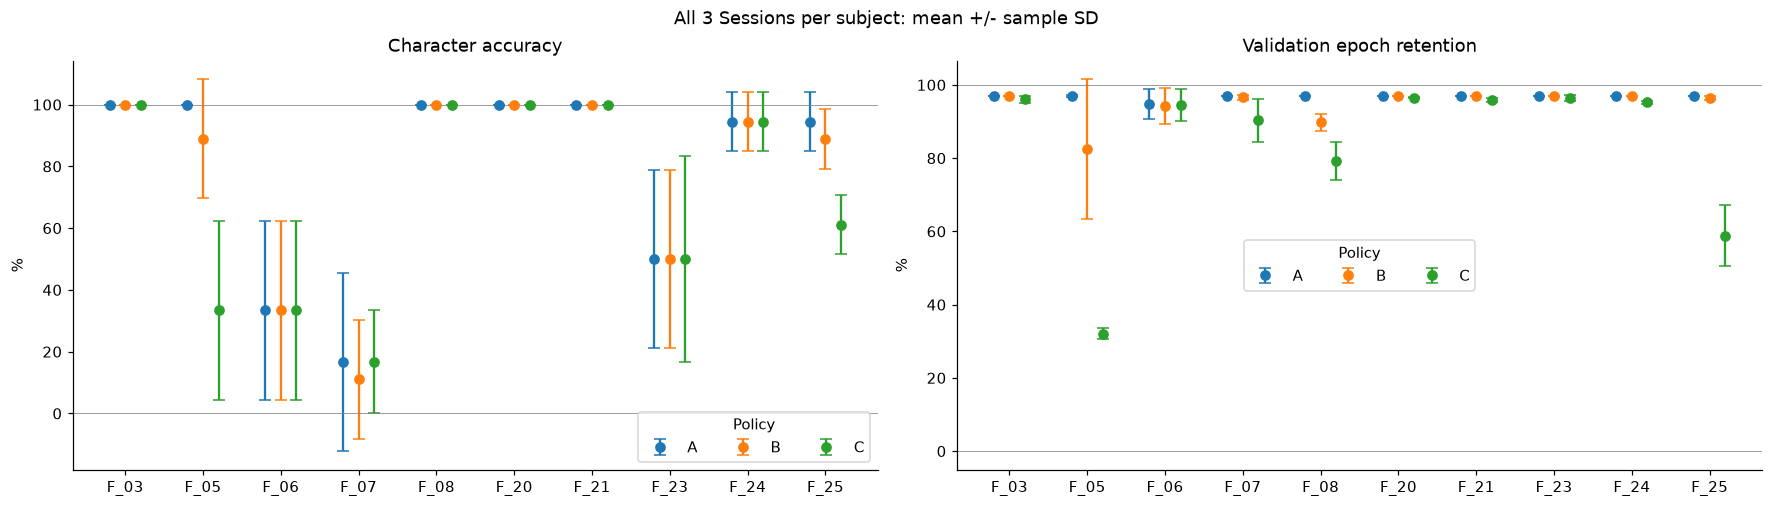

,policy,subject_id,validation_characters,correct_characters,character_accuracy,output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,mean_valid_flashes,no_output_characters
0,A,F_03,18,18,1.000000,18,0.00000,0.00000,122.333333,0
1,A,F_05,18,18,1.000000,18,0.00000,0.00000,122.111111,0
2,A,F_06,18,6,0.333333,18,0.00000,0.00000,119.388889,0
3,A,F_07,18,3,0.166667,18,0.00000,0.00000,122.333333,0
4,A,F_08,18,18,1.000000,18,0.00000,0.00000,122.333333,0
5,A,F_20,18,18,1.000000,18,0.00000,0.00000,122.333333,0
6,A,F_21,18,18,1.000000,18,0.00000,0.00000,122.333333,0
7,A,F_23,18,9,0.500000,18,0.00000,0.00000,122.333333,0
8,A,F_24,18,17,0.944444,18,0.00000,0.00000,122.333333,0
9,A,F_25,18,17,0.944444,18,0.00000,0.00000,122.333333,0


,policy,subject_id,session_id,validation_characters,correct_characters,character_accuracy,output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,mean_valid_flashes,no_output_characters,collected,kept,retention,scored
0,A,F_03,SE001,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
1,A,F_03,SE002,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
2,A,F_03,SE003,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
3,A,F_05,SE001,6,6,1.000000,6,0.00000,0.00000,121.666667,0,756,730,0.965608,730
4,A,F_05,SE002,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,C,F_24,SE002,6,5,0.833333,6,1.34375,1.34375,120.333333,0,756,722,0.955026,722
86,C,F_24,SE003,6,6,1.000000,6,1.34375,1.34375,119.333333,0,756,716,0.947090,716
87,C,F_25,SE001,6,3,0.500000,6,1.34375,1.34375,64.333333,0,756,386,0.510582,386
88,C,F_25,SE002,6,4,0.666667,6,1.34375,1.34375,72.833333,0,756,437,0.578042,437


In [9]:
session_metrics=sessions.merge(ret,on=['policy','subject_id','session_id'],validate='one_to_one')
subjects=sorted(sessions.subject_id.unique())
fig,axes=plt.subplots(1,2,figsize=(16,4.5),layout='constrained')
rows=[]
for ax,metric,title in zip(axes,['character_accuracy','retention'],['Character accuracy','Validation epoch retention']):
    for j,policy in enumerate(['A','B','C']):
        q=session_metrics.loc[session_metrics.policy.eq(policy)].groupby('subject_id')[metric].agg(['mean','std','count']).reindex(subjects)
        assert q['count'].eq(3).all()
        ax.errorbar(np.arange(len(subjects))+(j-1)*.2,q['mean']*100,yerr=q['std']*100,fmt='o',capsize=4,label=policy)
        for subject,r in q.iterrows():
            rows.append(dict(subject_id=subject,policy=policy,metric=metric,session_mean=r['mean'],session_sd=r['std'],n_sessions=int(r['count'])))
    ax.set(xticks=range(len(subjects)),xticklabels=subjects,ylabel='%',title=title)
    ax.axhline(0,color='grey',lw=.5);ax.axhline(100,color='grey',lw=.5)
    ax.legend(title='Policy',ncol=3)
fig.suptitle('All 3 Sessions per subject: mean +/- sample SD')
fig.savefig(OUT/'subject_model_errorbars.png',dpi=150)
plt.show()
pd.DataFrame(rows).to_csv(OUT/'subject_model_errorbars.csv',index=False)
display(pd.read_csv(OUT/'subject_character_summary.csv'))
display(session_metrics)


## 6. 每位被试的模型与字符明细

以下仅分开展示表格，不另画六张图。不同Session有独立模型；不会将未校准的模型分数拼成一个ROC。


In [10]:
model_details=models.merge(sessions,on=['model_id'] if 'model_id' in sessions else ['subject_id','session_id','policy','validation_characters'],validate='one_to_one')
for scope,label in [('own_valid_scored_epochs','own_auc'),('common_valid_scored_epochs_A_B_C','common_auc')]:
    model_details=model_details.merge(auc.loc[auc.scope.eq(scope),['model_id','policy','auc']].rename(columns={'auc':label}),on=['model_id','policy'],validate='one_to_one')
model_details.to_csv(OUT/'subject_session_model_results.csv',index=False)
for subject in subjects:
    display(Markdown(f'### {subject}'))
    display(model_details.loc[model_details.subject_id.eq(subject),['model_id','policy','training_characters','training_epochs','n_selected','correct_characters','validation_characters','no_output_characters','own_auc','common_auc']])
    display(pred.loc[pred.subject_id.eq(subject),['session_id','edf_name','character_trial_id','policy','true_character','predicted_character','correct','valid_flashes','prediction_status']].sort_values(['session_id','edf_name','character_trial_id','policy']))


### F_03

,model_id,policy,training_characters,training_epochs,n_selected,correct_characters,validation_characters,no_output_characters,own_auc,common_auc
0,F_03_SE001,A,12,1468,60,6,6,0,0.953737,0.953737
1,F_03_SE001,B,12,1468,60,6,6,0,0.953737,0.953737
2,F_03_SE001,C,12,1468,60,6,6,0,0.953737,0.953737
3,F_03_SE002,A,12,1468,53,6,6,0,0.843968,0.845891
4,F_03_SE002,B,12,1468,53,6,6,0,0.843968,0.845891
5,F_03_SE002,C,12,1457,53,6,6,0,0.843615,0.843615
6,F_03_SE003,A,12,1468,59,6,6,0,0.859244,0.864096
7,F_03_SE003,B,12,1468,59,6,6,0,0.859244,0.864096
8,F_03_SE003,C,12,1464,60,6,6,0,0.870670,0.870670


,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,correct,valid_flashes,prediction_status
0,SE001,F_03_SE001_CBCol_Train03.edf,1,A,D_1_4,D_1_4,True,104,predicted
6,SE001,F_03_SE001_CBCol_Train03.edf,1,B,D_1_4,D_1_4,True,104,predicted
12,SE001,F_03_SE001_CBCol_Train03.edf,1,C,D_1_4,D_1_4,True,104,predicted
1,SE001,F_03_SE001_CBCol_Train03.edf,2,A,E_1_5,E_1_5,True,126,predicted
7,SE001,F_03_SE001_CBCol_Train03.edf,2,B,E_1_5,E_1_5,True,126,predicted
13,SE001,F_03_SE001_CBCol_Train03.edf,2,C,E_1_5,E_1_5,True,126,predicted
2,SE001,F_03_SE001_CBCol_Train03.edf,3,A,G_2_1,G_2_1,True,126,predicted
8,SE001,F_03_SE001_CBCol_Train03.edf,3,B,G_2_1,G_2_1,True,126,predicted
14,SE001,F_03_SE001_CBCol_Train03.edf,3,C,G_2_1,G_2_1,True,126,predicted
3,SE001,F_03_SE001_CBCol_Train03.edf,4,A,R_3_6,R_3_6,True,126,predicted


### F_05

,model_id,policy,training_characters,training_epochs,n_selected,correct_characters,validation_characters,no_output_characters,own_auc,common_auc
9,F_05_SE001,A,12,1468,59,6,6,0,0.970152,0.933735
10,F_05_SE001,B,12,1409,60,6,6,0,0.968032,0.920348
11,F_05_SE001,C,12,729,46,1,6,3,0.630522,0.630522
12,F_05_SE002,A,12,1468,54,6,6,0,0.958331,0.876777
13,F_05_SE002,B,12,1130,57,4,6,1,0.885199,0.860190
14,F_05_SE002,C,12,562,21,4,6,1,0.959243,0.890995
15,F_05_SE003,A,12,1464,55,6,6,0,0.978977,0.954506
16,F_05_SE003,B,12,1455,49,6,6,0,0.976324,0.937339
17,F_05_SE003,C,12,524,29,1,6,2,0.612017,0.612017


,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,correct,valid_flashes,prediction_status
54,SE001,F_05_SE001_CBCol_Train04.edf,1,A,L_2_6,L_2_6,True,104,predicted
60,SE001,F_05_SE001_CBCol_Train04.edf,1,B,L_2_6,L_2_6,True,104,predicted
66,SE001,F_05_SE001_CBCol_Train04.edf,1,C,L_2_6,R_3_6,False,43,predicted
55,SE001,F_05_SE001_CBCol_Train04.edf,2,A,E_1_5,E_1_5,True,126,predicted
61,SE001,F_05_SE001_CBCol_Train04.edf,2,B,E_1_5,E_1_5,True,113,predicted
67,SE001,F_05_SE001_CBCol_Train04.edf,2,C,E_1_5,NaN,False,40,insufficient_evidence
56,SE001,F_05_SE001_CBCol_Train04.edf,3,A,A_1_1,A_1_1,True,126,predicted
62,SE001,F_05_SE001_CBCol_Train04.edf,3,B,A_1_1,A_1_1,True,115,predicted
68,SE001,F_05_SE001_CBCol_Train04.edf,3,C,A_1_1,A_1_1,True,39,predicted
57,SE001,F_05_SE001_CBCol_Train04.edf,4,A,D_1_4,D_1_4,True,122,predicted


... (20 outputs left out)

,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,correct,valid_flashes,prediction_status
432,SE001,F_24_SE001_CBCol_Train03.edf,1,A,U_4_3,U_4_3,True,104,predicted
438,SE001,F_24_SE001_CBCol_Train03.edf,1,B,U_4_3,U_4_3,True,104,predicted
444,SE001,F_24_SE001_CBCol_Train03.edf,1,C,U_4_3,U_4_3,True,98,predicted
433,SE001,F_24_SE001_CBCol_Train03.edf,2,A,S_4_1,S_4_1,True,126,predicted
439,SE001,F_24_SE001_CBCol_Train03.edf,2,B,S_4_1,S_4_1,True,126,predicted
445,SE001,F_24_SE001_CBCol_Train03.edf,2,C,S_4_1,S_4_1,True,126,predicted
434,SE001,F_24_SE001_CBCol_Train03.edf,3,A,E_1_5,E_1_5,True,126,predicted
440,SE001,F_24_SE001_CBCol_Train03.edf,3,B,E_1_5,E_1_5,True,126,predicted
446,SE001,F_24_SE001_CBCol_Train03.edf,3,C,E_1_5,E_1_5,True,126,predicted
435,SE001,F_24_SE001_CBCol_Train03.edf,4,A,F_1_6,F_1_6,True,126,predicted


### F_25

,model_id,policy,training_characters,training_epochs,n_selected,correct_characters,validation_characters,no_output_characters,own_auc,common_auc
81,F_25_SE001,A,12,1468,37,6,6,0,0.773717,0.756186
82,F_25_SE001,B,12,1452,33,5,6,0,0.766937,0.779922
83,F_25_SE001,C,12,792,21,3,6,0,0.713718,0.725928
84,F_25_SE002,A,12,1468,50,6,6,0,0.843722,0.841655
85,F_25_SE002,B,12,1468,50,6,6,0,0.843722,0.841655
86,F_25_SE002,C,12,1221,53,4,6,0,0.853386,0.853386
87,F_25_SE003,A,12,1468,39,5,6,0,0.793431,0.755774
88,F_25_SE003,B,12,1458,19,5,6,0,0.758924,0.717949
89,F_25_SE003,C,12,930,30,4,6,0,0.746829,0.746829


,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,correct,valid_flashes,prediction_status
486,SE001,F_25_SE001_CBCol_Train03.edf,1,A,O_3_3,O_3_3,True,104,predicted
492,SE001,F_25_SE001_CBCol_Train03.edf,1,B,O_3_3,O_3_3,True,104,predicted
498,SE001,F_25_SE001_CBCol_Train03.edf,1,C,O_3_3,2_5_5,False,45,predicted
487,SE001,F_25_SE001_CBCol_Train03.edf,2,A,T_4_2,T_4_2,True,126,predicted
493,SE001,F_25_SE001_CBCol_Train03.edf,2,B,T_4_2,F_1_6,False,123,predicted
499,SE001,F_25_SE001_CBCol_Train03.edf,2,C,T_4_2,T_4_2,True,66,predicted
488,SE001,F_25_SE001_CBCol_Train03.edf,3,A,H_2_2,H_2_2,True,126,predicted
494,SE001,F_25_SE001_CBCol_Train03.edf,3,B,H_2_2,H_2_2,True,124,predicted
500,SE001,F_25_SE001_CBCol_Train03.edf,3,C,H_2_2,N_3_2,False,43,predicted
489,SE001,F_25_SE001_CBCol_Train03.edf,4,A,E_1_5,E_1_5,True,126,predicted


## 7. 辅助AUC、等待与证据损失

own为各自保留的验证epoch；common为同一模型组三策略共同有效epoch。总体仅按30个模型组宏平均AUC，不拼接不同模型原始分数。时间按实际样本时钟取max(字符结束、该字符所有flash质量决策完成)，不逐flash累加等待；无输出的prediction_available_seconds为空。

C确认等待包括排除未来才确认的旧眨眼候选的保守等待。这里是回放数据可用时刻，未测量设备通信和逐epoch实机计算延迟。


In [11]:
display(pd.read_csv(OUT/'overall_macro_auc.csv'))
display(auc)
display(overall[['policy','mean_valid_flashes','no_output_characters','mean_decision_wait_after_trial_seconds','mean_output_wait_after_trial_seconds']])
display(pd.read_csv(OUT/'stimulus_group_flash_counts.csv').head(24))
display(pred[['policy','character_key','trial_end_seconds','evidence_ready_seconds','prediction_available_seconds']].head(18))


,policy,scope,model_folds,macro_auc
0,A,common_valid_scored_epochs_A_B_C,30,0.814291
1,A,own_valid_scored_epochs,30,0.819695
2,B,common_valid_scored_epochs_A_B_C,30,0.809608
3,B,own_valid_scored_epochs,30,0.814027
4,C,common_valid_scored_epochs_A_B_C,30,0.791948
5,C,own_valid_scored_epochs,30,0.793371


,model_id,policy,subject_id,session_id,site,scope,n_epochs,auc
0,F_03_SE001,A,F_03,SE001,ETSU,own_valid_scored_epochs,734,0.953737
1,F_03_SE001,B,F_03,SE001,ETSU,own_valid_scored_epochs,734,0.953737
2,F_03_SE001,C,F_03,SE001,ETSU,own_valid_scored_epochs,734,0.953737
3,F_03_SE001,A,F_03,SE001,ETSU,common_valid_scored_epochs_A_B_C,734,0.953737
4,F_03_SE001,B,F_03,SE001,ETSU,common_valid_scored_epochs_A_B_C,734,0.953737
...,...,...,...,...,...,...,...,...
175,F_25_SE003,B,F_25,SE003,ETSU,own_valid_scored_epochs,726,0.758924
176,F_25_SE003,C,F_25,SE003,ETSU,own_valid_scored_epochs,512,0.746829
177,F_25_SE003,A,F_25,SE003,ETSU,common_valid_scored_epochs_A_B_C,512,0.755774
178,F_25_SE003,B,F_25,SE003,ETSU,common_valid_scored_epochs_A_B_C,512,0.717949


,policy,mean_valid_flashes,no_output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds
0,A,122.016667,0,0.00000,0.00000
1,B,119.072222,1,0.00000,0.00000
2,C,105.244444,6,1.34375,1.34375


,model_id,policy,edf_name,character_key,stimulus_group_id,total_flashes,valid_flashes,scored_flashes
0,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_0312288a214b,1,0,0
1,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_06cc9cb80ee0,1,1,1
2,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_0b2959d0085f,1,1,1
3,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_105ac5f38689,1,1,1
4,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_106d3f6ec43f,1,1,1
5,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_123508c1928c,1,1,1
6,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_13a757b5535a,1,1,1
7,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_14ebf4bf52de,1,1,1
8,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_1629ba64cacc,1,1,1
9,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_1688d2cc969d,1,1,1


,policy,character_key,trial_end_seconds,evidence_ready_seconds,prediction_available_seconds
0,A,F_03_SE001_CBCol_Train03_T01,36.5625,36.56250,36.56250
1,A,F_03_SE001_CBCol_Train03_T02,71.5625,71.56250,71.56250
2,A,F_03_SE001_CBCol_Train03_T03,106.5625,106.56250,106.56250
3,A,F_03_SE001_CBCol_Train03_T04,141.5625,141.56250,141.56250
4,A,F_03_SE001_CBCol_Train03_T05,176.5625,176.56250,176.56250
5,A,F_03_SE001_CBCol_Train03_T06,211.5625,211.56250,211.56250
6,B,F_03_SE001_CBCol_Train03_T01,36.5625,36.56250,36.56250
7,B,F_03_SE001_CBCol_Train03_T02,71.5625,71.56250,71.56250
8,B,F_03_SE001_CBCol_Train03_T03,106.5625,106.56250,106.56250
9,B,F_03_SE001_CBCol_Train03_T04,141.5625,141.56250,141.56250


## 8. 全部StudyF结果与复现

本轮覆盖本地全部StudyF的10人、30个Session和90份Train EDF，不纳入StudyB或最终Test。A/B/C评价同一组验证字符，无输出计入总分母。比较准确率的变化、证据损失和确认等待，并检查各被试是否一致，不根据本轮结果修改检测参数。

预处理、特征及SWLDA参数与前轮一致。新增被试按完整清单纳入，没有按检测或分类表现挑选。每Session12个字符训练、6个验证；这与六人完整版具有相同校准预算，但比最初pilot预算更大。既有Train数据曾用于开发，本轮仍不是独立最终测试。站点映射沿用项目推断，保持inferred。

复现：run_all_studyf_preprocessing.py；run_swlda_rejection_experiment.py --config configs/swlda_all_studyf.json --output outputs/swlda_all_studyf_v3；audit_swlda_saved_experiment.py outputs/swlda_all_studyf_v3；build_three_session_experiment_notebook.py --all-studyf，然后运行本notebook。旧v1/v2结果均保留。


In [12]:
scores=pd.read_csv(OUT/'epoch_scores.csv',low_memory=False)
label_retention=scores.loc[scores.set.eq('validation')].groupby(['subject_id','session_id','policy','label']).agg(total=('would_keep','size'),kept=('would_keep','sum'),retention=('would_keep','mean')).reset_index()
label_retention.to_csv(OUT/'validation_label_retention.csv',index=False)
display(label_retention)
triggers=scores.loc[scores.set.eq('validation') & ~scores.would_keep,['subject_id','session_id','policy','trigger_channels']].copy()
triggers['channel']=triggers.trigger_channels.fillna('').str.split(';')
triggers=triggers.explode('channel')
trigger_summary=triggers.loc[triggers.channel.ne('')].groupby(['subject_id','session_id','policy','channel']).size().rename('triggered_epochs').reset_index()
trigger_summary.to_csv(OUT/'validation_trigger_channels.csv',index=False)
display(trigger_summary.sort_values('triggered_epochs',ascending=False).head(24))
assert scores.loc[~scores.would_keep,'target_score'].isna().all()
assert not scores.loc[~scores.would_keep,'has_score'].any()
n_validation=split.set.eq('validation').sum()
assert pred.groupby('policy').size().eq(n_validation).all()
assert pred.groupby('character_key').policy.nunique().eq(3).all()
assert pred.loc[~pred.output_available,'prediction_available_seconds'].isna().all()
assert not pred.loc[~pred.output_available,'correct'].any()
assert not record['used_final_test_data']
assert cfg['blink_interval_version']=='old_candidate_overlap_v1'
print('PASS: 90 EDFs, all 30 subject/Session groups; identical validation characters; no zero-filled rejected scores; no final Test')


,subject_id,session_id,policy,label,total,kept,retention
0,F_03,SE001,A,non-target,672,653,0.971726
1,F_03,SE001,A,target,84,81,0.964286
2,F_03,SE001,B,non-target,672,653,0.971726
3,F_03,SE001,B,target,84,81,0.964286
4,F_03,SE001,C,non-target,672,653,0.971726
...,...,...,...,...,...,...,...
175,F_25,SE003,A,target,84,82,0.976190
176,F_25,SE003,B,non-target,672,645,0.959821
177,F_25,SE003,B,target,84,81,0.964286
178,F_25,SE003,C,non-target,672,455,0.677083


,subject_id,session_id,policy,channel,triggered_epochs
7,F_05,SE002,B,EEG_F3,272
8,F_05,SE002,B,EEG_F4,210
19,F_08,SE001,B,EEG_F3,76
20,F_08,SE001,B,EEG_F4,65
21,F_08,SE001,B,EEG_Fz,59
9,F_05,SE002,B,EEG_Fz,55
2,F_05,SE001,B,EEG_F4,54
15,F_06,SE001,C,EEG_Oz,53
14,F_06,SE001,B,EEG_Oz,53
12,F_06,SE001,A,EEG_Oz,53


PASS: 90 EDFs, all 30 subject/Session groups; identical validation characters; no zero-filled rejected scores; no final Test


In [13]:
display(Markdown('### 三策略配对结论'))
comparison=pd.read_csv(OUT/'paired_strategy_summary.csv')
for row in comparison.itertuples():
    display(Markdown(f'{row.first}→{row.second}：新增正确{row.second_only_correct}个，损失{row.first_only_correct}个；准确率变化{row.accuracy_difference*100:+.2f}个百分点，平均额外等待{row.mean_extra_wait_seconds:.3f}秒。'))
display(models.groupby('fit_status').size().rename('models').to_frame())
display(pd.read_csv(OUT/'model_training_only_audit.csv'))
print('All StudyF Train files included; no StudyB and no final Test; no detector retuning.')


### 三策略配对结论

A→B：新增正确1个，损失5个；准确率变化-2.22个百分点，平均额外等待0.000秒。

A→C：新增正确3个，损失21个；准确率变化-10.00个百分点，平均额外等待1.344秒。

B→C：新增正确7个，损失21个；准确率变化-7.78个百分点，平均额外等待1.344秒。

,models
fit_status,
converged,67
max_features_reached,23


,model_id,policy,training_epochs,n_selected,max_final_selected_p,train_only_scaling_verified,saved_scores_verified
0,F_03_SE001,A,1468,60,0.146861,True,True
1,F_03_SE001,B,1468,60,0.146861,True,True
2,F_03_SE001,C,1468,60,0.146861,True,True
3,F_03_SE002,A,1468,53,0.143227,True,True
4,F_03_SE002,B,1468,53,0.143227,True,True
...,...,...,...,...,...,...,...
85,F_25_SE002,B,1468,50,0.091803,True,True
86,F_25_SE002,C,1221,53,0.095731,True,True
87,F_25_SE003,A,1468,39,0.087941,True,True
88,F_25_SE003,B,1458,19,0.137615,True,True


All StudyF Train files included; no StudyB and no final Test; no detector retuning.


---

## 历史实验 / 专项复核：bigp3bci_swlda_full_three_sessions

# 完整三Session：SWLDA与epoch拒绝策略

固定纳入F03、F05、F06、F08、F20、F25的SE001–SE003全部Train/CBCol EDF，共54份。每个被试×Session独立训练，Session内按EDF文件名与字符顺序取前2/3完整字符训练，其余验证。文件名顺序作为跨文件采集顺序代理，不推断未知的现实暂停。三策略复用同一划分；不读取最终Test。

A：基础故障与技术检查；B：A＋任一16通道PTP>150µV；C：A＋固定old_candidate_overlap_v1旧候选区间重叠拒绝。C保留原25µV额区幅值及其配套规则，不混用新版主波、恢复区间或局部突出度方案。滤波保持60Hz notch→0.5–30Hz因果滤波，逐EDF连续保留状态。


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/swlda_three_sessions.json').exists())
OUT=ROOT/'outputs/swlda_three_sessions_v2'
cfg=json.loads((OUT/'config_snapshot.json').read_text())
record=json.loads((OUT/'implementation_record.json').read_text())
models=pd.read_csv(OUT/'model_summary.csv')
pred=pd.read_csv(OUT/'character_predictions.csv')
split=pd.read_csv(OUT/'character_split.csv')
overall=pd.read_csv(OUT/'overall_character_summary.csv')
sessions=pd.read_csv(OUT/'session_character_summary.csv')
ret=pd.read_csv(OUT/'validation_retention.csv')
auc=pd.read_csv(OUT/'validation_auc.csv')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
display(pd.Series(record).to_frame('implementation'))


,implementation
classifier,"SWLDA, project-owned OLS forward/backward step..."
implementation_file,src/bigp3bci_swlda.py
implementation_sha256,03867b6ca5a91c0d5711d82683b3705082ba97dc7d1bf0...
reference,https://www.bci2000.org/mediawiki/index.php/Us...
source_config_sha256,140bc4b4002ac3e4d23b533d514ddb65c86eb076913ce6...
split_sha256,f08da8131e21726103e1fcd4e297ea3bdca306fe50bf72...
feature_count,256
models,54
training_characters,216
validation_characters,108


## 1. 数据覆盖、校准预算与划分

先固定完整字符划分，再筛选epoch。每个Session有3份EDF；拒绝后不会追加字符来补足训练epoch。校准预算按实际采集字符和记录时长统计，跨EDF未知间隔不计作已知时长。观察到的非126次flash字符原样保留，不为符合预期改数量。


In [2]:
manifest=pd.read_csv(ROOT/'outputs/full_three_session_preprocessing/selection_manifest.csv')
coverage=manifest.groupby(['subject_id','session_id']).size().unstack()
display(coverage)
assert coverage.shape==(6,3) and coverage.eq(3).all().all()
display(pd.read_csv(OUT/'character_inventory_and_split.csv'))
display(pd.read_csv(OUT/'calibration_and_retention.csv'))


session_id,SE001,SE002,SE003
subject_id,,,
F_03,3,3,3
F_05,3,3,3
F_06,3,3,3
F_08,3,3,3
F_20,3,3,3
F_25,3,3,3


,subject_id,session_id,set,character_trials,flashes
0,F_03,SE001,train,12,1512
1,F_03,SE001,validation,6,756
2,F_03,SE002,train,12,1512
3,F_03,SE002,validation,6,756
4,F_03,SE003,train,12,1512
5,F_03,SE003,validation,6,756
6,F_05,SE001,train,12,1512
7,F_05,SE001,validation,6,756
8,F_05,SE002,train,12,1512
9,F_05,SE002,validation,6,756


,model_id,policy,subject_id,session_id,site,fit_status,n_selected,training_characters,validation_characters,training_epochs,training_target_epochs,fit_cpu_wall_seconds,acquired_calibration_seconds,training_collected_flashes,validation_collected_flashes,training_kept_epochs,validation_kept_epochs
0,F_03_SE001,A,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.071332,423.125,1512,756,1468,734
1,F_03_SE001,B,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.064870,423.125,1512,756,1468,734
2,F_03_SE001,C,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.067653,423.125,1512,756,1468,734
3,F_03_SE002,A,F_03,SE002,ETSU,converged,53,12,6,1468,164,0.055820,423.125,1512,756,1468,734
4,F_03_SE002,B,F_03,SE002,ETSU,converged,53,12,6,1468,164,0.055677,423.125,1512,756,1468,734
5,F_03_SE002,C,F_03,SE002,ETSU,converged,53,12,6,1457,163,0.059335,423.125,1512,756,1457,721
6,F_03_SE003,A,F_03,SE003,ETSU,converged,59,12,6,1468,164,0.067600,423.125,1512,756,1468,734
7,F_03_SE003,B,F_03,SE003,ETSU,converged,59,12,6,1468,164,0.066038,423.125,1512,756,1468,734
8,F_03_SE003,C,F_03,SE003,ETSU,max_features_reached,60,12,6,1464,163,0.063104,423.125,1512,756,1464,724
9,F_05_SE001,A,F_05,SE001,Duke,converged,59,12,6,1468,163,0.062883,423.125,1512,756,1468,730


## 2. 映射与训练／验证边界核验

字符预测使用每次flash实际亮起的36个字符状态通道；StimulusCode不当字符编号。CurrentTarget仅用于真值和映射核验，不输入字符预测。集合边界检查共享原始样本以及训练策略确认是否进入验证期。连续因果滤波可使用历史状态，不使用未来验证样本拟合训练参数。


In [3]:
mapping=pd.read_csv(OUT/'mapping_audit.csv')
leak=pd.read_csv(OUT/'split_leakage_audit.csv')
display(mapping)
display(leak)
assert mapping.target_membership_label_disagreements.eq(0).all()
assert not leak.shared_raw_samples.any()
assert not leak.training_confirmation_enters_validation.any()


,edf_name,subject_id,session_id,n_flashes,n_character_state_channels,target_membership_label_disagreements,source_truth,prediction_mapping,true_ids_observed
0,F_03_SE001_CBCol_Train01.edf,F_03,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[5, 6, 18, 20, 21]"
1,F_03_SE001_CBCol_Train02.edf,F_03,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[3, 4, 5, 9, 22]"
2,F_03_SE001_CBCol_Train03.edf,F_03,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[4, 5, 7, 18]"
3,F_03_SE002_CBCol_Train01.edf,F_03,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 4, 7, 9, 14]"
4,F_03_SE002_CBCol_Train02.edf,F_03,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[4, 5, 15, 18, 19]"
5,F_03_SE002_CBCol_Train03.edf,F_03,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 5, 17, 18, 19, 21]"
6,F_03_SE003_CBCol_Train01.edf,F_03,SE003,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[4, 5, 9, 15, 18, 20]"
7,F_03_SE003_CBCol_Train02.edf,F_03,SE003,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 3, 4, 5, 19, 21]"
8,F_03_SE003_CBCol_Train03.edf,F_03,SE003,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[5, 9, 14, 15, 18, 19]"
9,F_05_SE001_CBCol_Train02.edf,F_05,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[2, 9, 13, 19, 20, 21]"


,edf_name,model_id,policy,raw_sample_gap,training_policy_to_first_validation_seconds,shared_raw_samples,training_confirmation_enters_validation,scope,train_edfs,validation_edfs
0,NaN,F_03_SE001,A,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE001_CBCol_Train01.edf;F_03_SE001_CBCol_...,F_03_SE001_CBCol_Train03.edf
1,NaN,F_03_SE001,B,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE001_CBCol_Train01.edf;F_03_SE001_CBCol_...,F_03_SE001_CBCol_Train03.edf
2,NaN,F_03_SE001,C,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE001_CBCol_Train01.edf;F_03_SE001_CBCol_...,F_03_SE001_CBCol_Train03.edf
3,NaN,F_03_SE002,A,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE002_CBCol_Train01.edf;F_03_SE002_CBCol_...,F_03_SE002_CBCol_Train03.edf
4,NaN,F_03_SE002,B,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE002_CBCol_Train01.edf;F_03_SE002_CBCol_...,F_03_SE002_CBCol_Train03.edf
5,NaN,F_03_SE002,C,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE002_CBCol_Train01.edf;F_03_SE002_CBCol_...,F_03_SE002_CBCol_Train03.edf
6,NaN,F_03_SE003,A,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE003_CBCol_Train01.edf;F_03_SE003_CBCol_...,F_03_SE003_CBCol_Train03.edf
7,NaN,F_03_SE003,B,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE003_CBCol_Train01.edf;F_03_SE003_CBCol_...,F_03_SE003_CBCol_Train03.edf
8,NaN,F_03_SE003,C,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_03_SE003_CBCol_Train01.edf;F_03_SE003_CBCol_...,F_03_SE003_CBCol_Train03.edf
9,NaN,F_05_SE001,A,NaN,NaN,False,False,independent_EDFs_separate_sample_clocks,F_05_SE001_CBCol_Train02.edf;F_05_SE001_CBCol_...,F_05_SE001_CBCol_Train04.edf


## 3. 固定特征与SWLDA

16通道×16个50ms平均电压窗＝256维；0–800ms，baseline=None。256Hz下205点，按整数样本时间归入相邻半开窗。各模型只在自己的保留训练epoch上估计标准化参数及筛选特征。

沿用项目内前向／后向逐步OLS SWLDA：进入p<0.10，移除p>0.15，最多60特征；不替换成普通LDA。参考[BCI2000 P300Classifier](https://www.bci2000.org/mediawiki/index.php/User_Reference:P300Classifier)，不声称逐位复现。选中特征、权重和选择过程保存在models子目录。


In [4]:
display(pd.Series(cfg['swlda']).to_frame('SWLDA settings'))
display(pd.read_csv(OUT/'feature_dictionary.csv').head(18))
display(models)
assert len(models)==54 and models.fit_status.isin(['converged','max_features_reached']).all()
assert models.n_selected.le(60).all()


,SWLDA settings
implementation,project-owned forward/backward OLS stepwise li...
p_enter,0.1
p_remove,0.15
max_features,60
max_steps,500
rank_tolerance,0.0
standardize,"training retained epochs only, population std;..."
class_weighting,None
reference,https://www.bci2000.org/mediawiki/index.php/Us...
reproduction_limit,classic stepwise SWLDA algorithm on requested ...


,feature_index,channel,bin_index,start_ms,end_ms
0,0,EEG_F3,0,0,50
1,1,EEG_F3,1,50,100
2,2,EEG_F3,2,100,150
3,3,EEG_F3,3,150,200
4,4,EEG_F3,4,200,250
5,5,EEG_F3,5,250,300
6,6,EEG_F3,6,300,350
7,7,EEG_F3,7,350,400
8,8,EEG_F3,8,400,450
9,9,EEG_F3,9,450,500


,model_id,policy,subject_id,session_id,site,fit_status,n_selected,training_characters,validation_characters,training_epochs,training_target_epochs,fit_cpu_wall_seconds,acquired_calibration_seconds
0,F_03_SE001,A,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.071332,423.125
1,F_03_SE001,B,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.064870,423.125
2,F_03_SE001,C,F_03,SE001,ETSU,max_features_reached,60,12,6,1468,162,0.067653,423.125
3,F_03_SE002,A,F_03,SE002,ETSU,converged,53,12,6,1468,164,0.055820,423.125
4,F_03_SE002,B,F_03,SE002,ETSU,converged,53,12,6,1468,164,0.055677,423.125
5,F_03_SE002,C,F_03,SE002,ETSU,converged,53,12,6,1457,163,0.059335,423.125
6,F_03_SE003,A,F_03,SE003,ETSU,converged,59,12,6,1468,164,0.067600,423.125
7,F_03_SE003,B,F_03,SE003,ETSU,converged,59,12,6,1468,164,0.066038,423.125
8,F_03_SE003,C,F_03,SE003,ETSU,max_features_reached,60,12,6,1464,163,0.063104,423.125
9,F_05_SE001,A,F_05,SE001,Duke,converged,59,12,6,1468,163,0.062883,423.125


## 4. 总体与配对字符结果

同一组验证字符保留在三策略分母中，无输出计为错误。拒绝flash的分数为空，不填0。字符证据为“亮起时平均target分数－未亮起时平均分数”；36个候选均须有亮起和未亮起证据，否则无输出。此规则未依据结果调整。


In [5]:
display(overall)
validation_ret=ret.groupby('policy',as_index=False)[['collected','kept']].sum()
validation_ret['retention']=validation_ret.kept/validation_ret.collected
display(validation_ret)
display(pd.read_csv(OUT/'paired_strategy_summary.csv'))
display(pd.read_csv(OUT/'paired_character_comparison.csv'))
summary=overall.set_index('policy')
display(Markdown('本轮字符准确率：'+ '；'.join(f"{p}为{int(summary.loc[p,'correct_characters'])}/{int(summary.loc[p,'validation_characters'])}（{summary.loc[p,'character_accuracy']:.2%}），无输出{int(summary.loc[p,'no_output_characters'])}个" for p in ['A','B','C'])+'。无输出均保留在总分母中。'))


,policy,validation_characters,correct_characters,character_accuracy,output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,mean_valid_flashes,no_output_characters
0,A,108,95,0.879630,108,0.00000,0.00000,121.805556,0
1,B,108,92,0.851852,107,0.00000,0.00000,117.000000,1
2,C,108,77,0.712963,102,1.34375,1.34375,96.037037,6


,policy,collected,kept,retention
0,A,13608,13155,0.966711
1,B,13608,12636,0.928571
2,C,13608,10372,0.762199


,first,second,characters,second_only_correct,first_only_correct,accuracy_difference,paired_exact_binomial_p,mean_extra_wait_seconds,note
0,A,B,108,1,4,-0.027778,0.375000,0.00000,descriptive paired development comparison; no ...
1,A,C,108,0,18,-0.166667,0.000008,1.34375,descriptive paired development comparison; no ...
2,B,C,108,3,18,-0.138889,0.001490,1.34375,descriptive paired development comparison; no ...


,model_id,edf_name,character_key,true_character,correct_A,correct_B,correct_C,predicted_character_A,predicted_character_B,predicted_character_C,...,output_available_C,valid_flashes_A,valid_flashes_B,valid_flashes_C,prediction_available_seconds_A,prediction_available_seconds_B,prediction_available_seconds_C,evidence_ready_seconds_A,evidence_ready_seconds_B,evidence_ready_seconds_C
0,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,D_1_4,True,True,True,D_1_4,D_1_4,D_1_4,...,True,104,104,104,36.5625,36.5625,37.90625,36.5625,36.5625,37.90625
1,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T02,E_1_5,True,True,True,E_1_5,E_1_5,E_1_5,...,True,126,126,126,71.5625,71.5625,72.90625,71.5625,71.5625,72.90625
2,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T03,G_2_1,True,True,True,G_2_1,G_2_1,G_2_1,...,True,126,126,126,106.5625,106.5625,107.90625,106.5625,106.5625,107.90625
3,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T04,R_3_6,True,True,True,R_3_6,R_3_6,R_3_6,...,True,126,126,126,141.5625,141.5625,142.90625,141.5625,141.5625,142.90625
4,F_03_SE001,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T05,E_1_5,True,True,True,E_1_5,E_1_5,E_1_5,...,True,126,126,126,176.5625,176.5625,177.90625,176.5625,176.5625,177.90625
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,F_25_SE003,F_25_SE003_CBCol_Train03.edf,F_25_SE003_CBCol_Train03_T02,I_2_3,True,False,False,I_2_3,Z_5_2,J_2_4,...,True,126,121,63,71.5625,71.5625,72.90625,71.5625,71.5625,72.90625
104,F_25_SE003,F_25_SE003_CBCol_Train03.edf,F_25_SE003_CBCol_Train03_T03,S_4_1,True,True,True,S_4_1,S_4_1,S_4_1,...,True,126,123,105,106.5625,106.5625,107.90625,106.5625,106.5625,107.90625
105,F_25_SE003,F_25_SE003_CBCol_Train03.edf,F_25_SE003_CBCol_Train03_T04,U_4_3,False,True,False,A_1_1,U_4_3,Sp_5_3,...,True,126,126,94,141.5625,141.5625,142.90625,141.5625,141.5625,142.90625
106,F_25_SE003,F_25_SE003_CBCol_Train03.edf,F_25_SE003_CBCol_Train03_T05,A_1_1,True,True,True,A_1_1,A_1_1,A_1_1,...,True,126,126,112,176.5625,176.5625,177.90625,176.5625,176.5625,177.90625


本轮字符准确率：A为95/108（87.96%），无输出0个；B为92/108（85.19%），无输出1个；C为77/108（71.30%），无输出6个。无输出均保留在总分母中。

## 5. 六人合并误差线图：完整三Session

左右分别为字符准确率与验证epoch保留率；点为3个Session的等权均值，误差线为±1个Session间样本标准差，不是置信区间。误差线可能超出0–100%，不截短。下方按字符数汇总的表与此均值在各Session分母不同时可能不同。


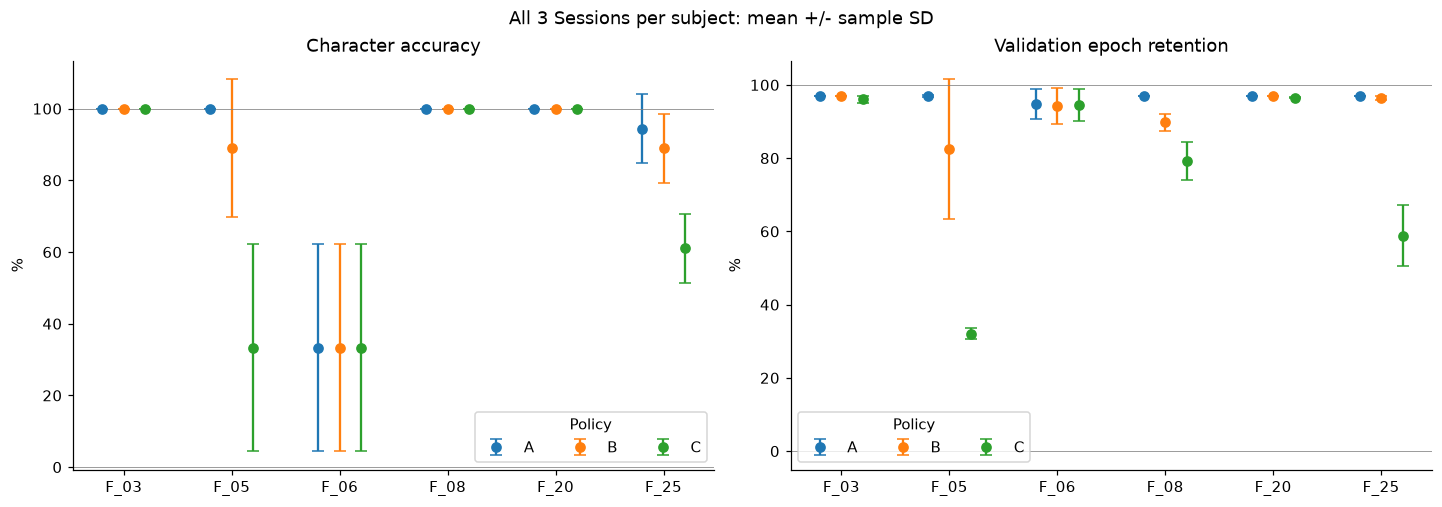

,policy,subject_id,validation_characters,correct_characters,character_accuracy,output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,mean_valid_flashes,no_output_characters
0,A,F_03,18,18,1.000000,18,0.00000,0.00000,122.333333,0
1,A,F_05,18,18,1.000000,18,0.00000,0.00000,122.111111,0
2,A,F_06,18,6,0.333333,18,0.00000,0.00000,119.388889,0
3,A,F_08,18,18,1.000000,18,0.00000,0.00000,122.333333,0
4,A,F_20,18,18,1.000000,18,0.00000,0.00000,122.333333,0
5,A,F_25,18,17,0.944444,18,0.00000,0.00000,122.333333,0
6,B,F_03,18,18,1.000000,18,0.00000,0.00000,122.333333,0
7,B,F_05,18,16,0.888889,17,0.00000,0.00000,103.888889,1
8,B,F_06,18,6,0.333333,18,0.00000,0.00000,118.722222,0
9,B,F_08,18,18,1.000000,18,0.00000,0.00000,113.111111,0


,policy,subject_id,session_id,validation_characters,correct_characters,character_accuracy,output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,mean_valid_flashes,no_output_characters,collected,kept,retention,scored
0,A,F_03,SE001,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
1,A,F_03,SE002,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
2,A,F_03,SE003,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
3,A,F_05,SE001,6,6,1.000000,6,0.00000,0.00000,121.666667,0,756,730,0.965608,730
4,A,F_05,SE002,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
5,A,F_05,SE003,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
6,A,F_06,SE001,6,3,0.500000,6,0.00000,0.00000,113.500000,0,756,681,0.900794,681
7,A,F_06,SE002,6,3,0.500000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
8,A,F_06,SE003,6,0,0.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734
9,A,F_08,SE001,6,6,1.000000,6,0.00000,0.00000,122.333333,0,756,734,0.970899,734


In [6]:
session_metrics=sessions.merge(ret,on=['policy','subject_id','session_id'],validate='one_to_one')
subjects=sorted(sessions.subject_id.unique())
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
rows=[]
for ax,metric,title in zip(axes,['character_accuracy','retention'],['Character accuracy','Validation epoch retention']):
    for j,policy in enumerate(['A','B','C']):
        q=session_metrics.loc[session_metrics.policy.eq(policy)].groupby('subject_id')[metric].agg(['mean','std','count']).reindex(subjects)
        assert q['count'].eq(3).all()
        ax.errorbar(np.arange(6)+(j-1)*.2,q['mean']*100,yerr=q['std']*100,fmt='o',capsize=4,label=policy)
        for subject,r in q.iterrows():
            rows.append(dict(subject_id=subject,policy=policy,metric=metric,session_mean=r['mean'],session_sd=r['std'],n_sessions=int(r['count'])))
    ax.set(xticks=range(6),xticklabels=subjects,ylabel='%',title=title)
    ax.axhline(0,color='grey',lw=.5);ax.axhline(100,color='grey',lw=.5)
    ax.legend(title='Policy',ncol=3)
fig.suptitle('All 3 Sessions per subject: mean +/- sample SD')
fig.savefig(OUT/'subject_model_errorbars.png',dpi=150)
plt.show()
pd.DataFrame(rows).to_csv(OUT/'subject_model_errorbars.csv',index=False)
display(pd.read_csv(OUT/'subject_character_summary.csv'))
display(session_metrics)


## 6. 每位被试的模型与字符明细

以下仅分开展示表格，不另画六张图。不同Session有独立模型；不会将未校准的模型分数拼成一个ROC。


In [7]:
model_details=models.merge(sessions,on=['model_id'] if 'model_id' in sessions else ['subject_id','session_id','policy','validation_characters'],validate='one_to_one')
for scope,label in [('own_valid_scored_epochs','own_auc'),('common_valid_scored_epochs_A_B_C','common_auc')]:
    model_details=model_details.merge(auc.loc[auc.scope.eq(scope),['model_id','policy','auc']].rename(columns={'auc':label}),on=['model_id','policy'],validate='one_to_one')
model_details.to_csv(OUT/'subject_session_model_results.csv',index=False)
for subject in subjects:
    display(Markdown(f'### {subject}'))
    display(model_details.loc[model_details.subject_id.eq(subject),['model_id','policy','training_characters','training_epochs','n_selected','correct_characters','validation_characters','no_output_characters','own_auc','common_auc']])
    display(pred.loc[pred.subject_id.eq(subject),['session_id','edf_name','character_trial_id','policy','true_character','predicted_character','correct','valid_flashes','prediction_status']].sort_values(['session_id','edf_name','character_trial_id','policy']))


### F_03

,model_id,policy,training_characters,training_epochs,n_selected,correct_characters,validation_characters,no_output_characters,own_auc,common_auc
0,F_03_SE001,A,12,1468,60,6,6,0,0.953737,0.953737
1,F_03_SE001,B,12,1468,60,6,6,0,0.953737,0.953737
2,F_03_SE001,C,12,1468,60,6,6,0,0.953737,0.953737
3,F_03_SE002,A,12,1468,53,6,6,0,0.843968,0.845891
4,F_03_SE002,B,12,1468,53,6,6,0,0.843968,0.845891
5,F_03_SE002,C,12,1457,53,6,6,0,0.843615,0.843615
6,F_03_SE003,A,12,1468,59,6,6,0,0.859244,0.864096
7,F_03_SE003,B,12,1468,59,6,6,0,0.859244,0.864096
8,F_03_SE003,C,12,1464,60,6,6,0,0.870670,0.870670


,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,correct,valid_flashes,prediction_status
0,SE001,F_03_SE001_CBCol_Train03.edf,1,A,D_1_4,D_1_4,True,104,predicted
6,SE001,F_03_SE001_CBCol_Train03.edf,1,B,D_1_4,D_1_4,True,104,predicted
12,SE001,F_03_SE001_CBCol_Train03.edf,1,C,D_1_4,D_1_4,True,104,predicted
1,SE001,F_03_SE001_CBCol_Train03.edf,2,A,E_1_5,E_1_5,True,126,predicted
7,SE001,F_03_SE001_CBCol_Train03.edf,2,B,E_1_5,E_1_5,True,126,predicted
13,SE001,F_03_SE001_CBCol_Train03.edf,2,C,E_1_5,E_1_5,True,126,predicted
2,SE001,F_03_SE001_CBCol_Train03.edf,3,A,G_2_1,G_2_1,True,126,predicted
8,SE001,F_03_SE001_CBCol_Train03.edf,3,B,G_2_1,G_2_1,True,126,predicted
14,SE001,F_03_SE001_CBCol_Train03.edf,3,C,G_2_1,G_2_1,True,126,predicted
3,SE001,F_03_SE001_CBCol_Train03.edf,4,A,R_3_6,R_3_6,True,126,predicted


### F_05

,model_id,policy,training_characters,training_epochs,n_selected,correct_characters,validation_characters,no_output_characters,own_auc,common_auc
9,F_05_SE001,A,12,1468,59,6,6,0,0.970152,0.933735
10,F_05_SE001,B,12,1409,60,6,6,0,0.968032,0.920348
11,F_05_SE001,C,12,729,46,1,6,3,0.630522,0.630522
12,F_05_SE002,A,12,1468,54,6,6,0,0.958331,0.876777
13,F_05_SE002,B,12,1130,57,4,6,1,0.885199,0.860190
14,F_05_SE002,C,12,562,21,4,6,1,0.959243,0.890995
15,F_05_SE003,A,12,1464,55,6,6,0,0.978977,0.954506
16,F_05_SE003,B,12,1455,49,6,6,0,0.976324,0.937339
17,F_05_SE003,C,12,524,29,1,6,2,0.612017,0.612017


,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,correct,valid_flashes,prediction_status
54,SE001,F_05_SE001_CBCol_Train04.edf,1,A,L_2_6,L_2_6,True,104,predicted
60,SE001,F_05_SE001_CBCol_Train04.edf,1,B,L_2_6,L_2_6,True,104,predicted
66,SE001,F_05_SE001_CBCol_Train04.edf,1,C,L_2_6,R_3_6,False,43,predicted
55,SE001,F_05_SE001_CBCol_Train04.edf,2,A,E_1_5,E_1_5,True,126,predicted
61,SE001,F_05_SE001_CBCol_Train04.edf,2,B,E_1_5,E_1_5,True,113,predicted
67,SE001,F_05_SE001_CBCol_Train04.edf,2,C,E_1_5,NaN,False,40,insufficient_evidence
56,SE001,F_05_SE001_CBCol_Train04.edf,3,A,A_1_1,A_1_1,True,126,predicted
62,SE001,F_05_SE001_CBCol_Train04.edf,3,B,A_1_1,A_1_1,True,115,predicted
68,SE001,F_05_SE001_CBCol_Train04.edf,3,C,A_1_1,A_1_1,True,39,predicted
57,SE001,F_05_SE001_CBCol_Train04.edf,4,A,D_1_4,D_1_4,True,122,predicted


... (8 outputs left out)

,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,correct,valid_flashes,prediction_status
216,SE001,F_20_SE001_CBCol_Train03.edf,1,A,B_1_2,B_1_2,True,104,predicted
222,SE001,F_20_SE001_CBCol_Train03.edf,1,B,B_1_2,B_1_2,True,104,predicted
228,SE001,F_20_SE001_CBCol_Train03.edf,1,C,B_1_2,B_1_2,True,104,predicted
217,SE001,F_20_SE001_CBCol_Train03.edf,2,A,O_3_3,O_3_3,True,126,predicted
223,SE001,F_20_SE001_CBCol_Train03.edf,2,B,O_3_3,O_3_3,True,126,predicted
229,SE001,F_20_SE001_CBCol_Train03.edf,2,C,O_3_3,O_3_3,True,126,predicted
218,SE001,F_20_SE001_CBCol_Train03.edf,3,A,T_4_2,T_4_2,True,126,predicted
224,SE001,F_20_SE001_CBCol_Train03.edf,3,B,T_4_2,T_4_2,True,126,predicted
230,SE001,F_20_SE001_CBCol_Train03.edf,3,C,T_4_2,T_4_2,True,123,predicted
219,SE001,F_20_SE001_CBCol_Train03.edf,4,A,T_4_2,T_4_2,True,126,predicted


### F_25

,model_id,policy,training_characters,training_epochs,n_selected,correct_characters,validation_characters,no_output_characters,own_auc,common_auc
45,F_25_SE001,A,12,1468,37,6,6,0,0.773717,0.756186
46,F_25_SE001,B,12,1452,33,5,6,0,0.766937,0.779922
47,F_25_SE001,C,12,792,21,3,6,0,0.713718,0.725928
48,F_25_SE002,A,12,1468,50,6,6,0,0.843722,0.841655
49,F_25_SE002,B,12,1468,50,6,6,0,0.843722,0.841655
50,F_25_SE002,C,12,1221,53,4,6,0,0.853386,0.853386
51,F_25_SE003,A,12,1468,39,5,6,0,0.793431,0.755774
52,F_25_SE003,B,12,1458,19,5,6,0,0.758924,0.717949
53,F_25_SE003,C,12,930,30,4,6,0,0.746829,0.746829


,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,correct,valid_flashes,prediction_status
270,SE001,F_25_SE001_CBCol_Train03.edf,1,A,O_3_3,O_3_3,True,104,predicted
276,SE001,F_25_SE001_CBCol_Train03.edf,1,B,O_3_3,O_3_3,True,104,predicted
282,SE001,F_25_SE001_CBCol_Train03.edf,1,C,O_3_3,2_5_5,False,45,predicted
271,SE001,F_25_SE001_CBCol_Train03.edf,2,A,T_4_2,T_4_2,True,126,predicted
277,SE001,F_25_SE001_CBCol_Train03.edf,2,B,T_4_2,F_1_6,False,123,predicted
283,SE001,F_25_SE001_CBCol_Train03.edf,2,C,T_4_2,T_4_2,True,66,predicted
272,SE001,F_25_SE001_CBCol_Train03.edf,3,A,H_2_2,H_2_2,True,126,predicted
278,SE001,F_25_SE001_CBCol_Train03.edf,3,B,H_2_2,H_2_2,True,124,predicted
284,SE001,F_25_SE001_CBCol_Train03.edf,3,C,H_2_2,N_3_2,False,43,predicted
273,SE001,F_25_SE001_CBCol_Train03.edf,4,A,E_1_5,E_1_5,True,126,predicted


## 7. 辅助AUC、等待与证据损失

own为各自保留的验证epoch；common为同一模型组三策略共同有效epoch。总体仅按18个模型组宏平均AUC，不拼接不同模型原始分数。时间按实际样本时钟取max(字符结束、该字符所有flash质量决策完成)，不逐flash累加等待；无输出的prediction_available_seconds为空。

C确认等待包括排除未来才确认的旧眨眼候选的保守等待。这里是回放数据可用时刻，未测量设备通信和逐epoch实机计算延迟。


In [8]:
display(pd.read_csv(OUT/'overall_macro_auc.csv'))
display(auc)
display(overall[['policy','mean_valid_flashes','no_output_characters','mean_decision_wait_after_trial_seconds','mean_output_wait_after_trial_seconds']])
display(pd.read_csv(OUT/'stimulus_group_flash_counts.csv').head(24))
display(pred[['policy','character_key','trial_end_seconds','evidence_ready_seconds','prediction_available_seconds']].head(18))


,policy,scope,model_folds,macro_auc
0,A,common_valid_scored_epochs_A_B_C,18,0.850848
1,A,own_valid_scored_epochs,18,0.860170
2,B,common_valid_scored_epochs_A_B_C,18,0.847406
3,B,own_valid_scored_epochs,18,0.854498
4,C,common_valid_scored_epochs_A_B_C,18,0.813616
5,C,own_valid_scored_epochs,18,0.815919


,model_id,policy,subject_id,session_id,site,scope,n_epochs,auc
0,F_03_SE001,A,F_03,SE001,ETSU,own_valid_scored_epochs,734,0.953737
1,F_03_SE001,B,F_03,SE001,ETSU,own_valid_scored_epochs,734,0.953737
2,F_03_SE001,C,F_03,SE001,ETSU,own_valid_scored_epochs,734,0.953737
3,F_03_SE001,A,F_03,SE001,ETSU,common_valid_scored_epochs_A_B_C,734,0.953737
4,F_03_SE001,B,F_03,SE001,ETSU,common_valid_scored_epochs_A_B_C,734,0.953737
...,...,...,...,...,...,...,...,...
103,F_25_SE003,B,F_25,SE003,ETSU,own_valid_scored_epochs,726,0.758924
104,F_25_SE003,C,F_25,SE003,ETSU,own_valid_scored_epochs,512,0.746829
105,F_25_SE003,A,F_25,SE003,ETSU,common_valid_scored_epochs_A_B_C,512,0.755774
106,F_25_SE003,B,F_25,SE003,ETSU,common_valid_scored_epochs_A_B_C,512,0.717949


,policy,mean_valid_flashes,no_output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds
0,A,121.805556,0,0.00000,0.00000
1,B,117.000000,1,0.00000,0.00000
2,C,96.037037,6,1.34375,1.34375


,model_id,policy,edf_name,character_key,stimulus_group_id,total_flashes,valid_flashes,scored_flashes
0,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_0312288a214b,1,0,0
1,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_06cc9cb80ee0,1,1,1
2,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_0b2959d0085f,1,1,1
3,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_105ac5f38689,1,1,1
4,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_106d3f6ec43f,1,1,1
5,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_123508c1928c,1,1,1
6,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_13a757b5535a,1,1,1
7,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_14ebf4bf52de,1,1,1
8,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_1629ba64cacc,1,1,1
9,F_03_SE001,A,F_03_SE001_CBCol_Train03.edf,F_03_SE001_CBCol_Train03_T01,observed_1688d2cc969d,1,1,1


,policy,character_key,trial_end_seconds,evidence_ready_seconds,prediction_available_seconds
0,A,F_03_SE001_CBCol_Train03_T01,36.5625,36.56250,36.56250
1,A,F_03_SE001_CBCol_Train03_T02,71.5625,71.56250,71.56250
2,A,F_03_SE001_CBCol_Train03_T03,106.5625,106.56250,106.56250
3,A,F_03_SE001_CBCol_Train03_T04,141.5625,141.56250,141.56250
4,A,F_03_SE001_CBCol_Train03_T05,176.5625,176.56250,176.56250
5,A,F_03_SE001_CBCol_Train03_T06,211.5625,211.56250,211.56250
6,B,F_03_SE001_CBCol_Train03_T01,36.5625,36.56250,36.56250
7,B,F_03_SE001_CBCol_Train03_T02,71.5625,71.56250,71.56250
8,B,F_03_SE001_CBCol_Train03_T03,106.5625,106.56250,106.56250
9,B,F_03_SE001_CBCol_Train03_T04,141.5625,141.56250,141.56250


## 8. 如何解释与复现

比较完整字符准确率的收益，是否抵消证据丢失、无输出和确认等待；同时检查被试及Session差异。这里扩大了数据覆盖和每Session训练预算，不能将相较旧pilot的变化单独归因为Session数量。已有Train记录参与过预处理开发，因此本轮仍属开发对照，不是独立最终测试。不据本轮结果继续调整眨眼参数。

复现顺序：run_full_three_session_preprocessing.py；run_swlda_rejection_experiment.py --config configs/swlda_three_sessions.json --output outputs/swlda_three_sessions_v2；build_three_session_experiment_notebook.py，然后运行本notebook。原v1结果保留。

本轮A/B/C正确字符数分别为95/92/77（各108个）。PTP150µV未带来总体收益；旧区间眨眼拒绝同样没有抵消证据损失及约1.34秒额外确认等待。与A配对比较，B新增正确1个但损失4个，C没有新增正确字符、损失18个。C的6个无输出均来自F05；F05和F25的字符结果下降，F06三策略均仅6/18，后者原因尚未确认，不能直接归为眨眼问题。这些是当前开发数据上的描述结果，不能推广为所有眨眼处理都无效。

54个模型中40个正常收敛，14个达到预设60特征上限，均按固定设置结束。独立审计已验证全部模型的训练集标准化、保存分数及最终特征移除标准；39项单元测试通过。


In [9]:
scores=pd.read_csv(OUT/'epoch_scores.csv',low_memory=False)
label_retention=scores.loc[scores.set.eq('validation')].groupby(['subject_id','session_id','policy','label']).agg(total=('would_keep','size'),kept=('would_keep','sum'),retention=('would_keep','mean')).reset_index()
label_retention.to_csv(OUT/'validation_label_retention.csv',index=False)
display(label_retention)
triggers=scores.loc[scores.set.eq('validation') & ~scores.would_keep,['subject_id','session_id','policy','trigger_channels']].copy()
triggers['channel']=triggers.trigger_channels.fillna('').str.split(';')
triggers=triggers.explode('channel')
trigger_summary=triggers.loc[triggers.channel.ne('')].groupby(['subject_id','session_id','policy','channel']).size().rename('triggered_epochs').reset_index()
trigger_summary.to_csv(OUT/'validation_trigger_channels.csv',index=False)
display(trigger_summary.sort_values('triggered_epochs',ascending=False).head(24))
assert scores.loc[~scores.would_keep,'target_score'].isna().all()
assert not scores.loc[~scores.would_keep,'has_score'].any()
n_validation=split.set.eq('validation').sum()
assert pred.groupby('policy').size().eq(n_validation).all()
assert pred.groupby('character_key').policy.nunique().eq(3).all()
assert pred.loc[~pred.output_available,'prediction_available_seconds'].isna().all()
assert not pred.loc[~pred.output_available,'correct'].any()
assert not record['used_final_test_data']
assert cfg['blink_interval_version']=='old_candidate_overlap_v1'
print('PASS: 54 EDFs, all 18 subject/Session groups; identical validation characters; no zero-filled rejected scores; no final Test')


,subject_id,session_id,policy,label,total,kept,retention
0,F_03,SE001,A,non-target,672,653,0.971726
1,F_03,SE001,A,target,84,81,0.964286
2,F_03,SE001,B,non-target,672,653,0.971726
3,F_03,SE001,B,target,84,81,0.964286
4,F_03,SE001,C,non-target,672,653,0.971726
...,...,...,...,...,...,...,...
103,F_25,SE003,A,target,84,82,0.976190
104,F_25,SE003,B,non-target,672,645,0.959821
105,F_25,SE003,B,target,84,81,0.964286
106,F_25,SE003,C,non-target,672,455,0.677083


,subject_id,session_id,policy,channel,triggered_epochs
7,F_05,SE002,B,EEG_F3,272
8,F_05,SE002,B,EEG_F4,210
16,F_08,SE001,B,EEG_F3,76
17,F_08,SE001,B,EEG_F4,65
18,F_08,SE001,B,EEG_Fz,59
9,F_05,SE002,B,EEG_Fz,55
2,F_05,SE001,B,EEG_F4,54
12,F_06,SE001,A,EEG_Oz,53
14,F_06,SE001,B,EEG_Oz,53
15,F_06,SE001,C,EEG_Oz,53


PASS: 54 EDFs, all 18 subject/Session groups; identical validation characters; no zero-filled rejected scores; no final Test


---

## 历史实验 / 专项复核：bigp3bci_swlda_rejection_experiment

# SWLDA：三种epoch拒绝策略的字符识别对照

本轮实际训练并验证33个SWLDA模型，使用现有12份Train/CBCol EDF、6名被试、11个被试×Session模型组。没有使用最终Test数据，没有训练PTP 250µV重复组，也没有加入8/12/18µV突出度试验。

A：仅基础故障与技术有效性检查。B：A＋16通道任一PTP>150µV拒绝。C：A＋**old_candidate_overlap_v1旧候选区间**重叠拒绝。C使用原25µV额区幅值及原配套触发条件，不使用新版主波或主波＋恢复区间。它是曾得到2105个额外区间关联epoch的旧版本；本轮结论仅适用于这一固定版本。

固定48个训练字符和24个验证字符。所有策略评价同一组24个验证字符；无输出仍计入准确率分母。结果属于小样本开发对照，不是独立最终评测。


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/swlda_rejection_experiment.json').exists())
OUT=ROOT/'outputs/swlda_rejection_experiment_v1'
config=json.loads((OUT/'config_snapshot.json').read_text())
record=json.loads((OUT/'implementation_record.json').read_text())
split=pd.read_csv(OUT/'character_split.csv')
pred=pd.read_csv(OUT/'character_predictions.csv')
models=pd.read_csv(OUT/'model_summary.csv')
auc=pd.read_csv(OUT/'validation_auc.csv')
overall=pd.read_csv(OUT/'overall_character_summary.csv')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
display(pd.Series(record,name='implementation and scope').to_frame())


,implementation and scope
classifier,"SWLDA, project-owned OLS forward/backward step..."
implementation_file,src/bigp3bci_swlda.py
implementation_sha256,03867b6ca5a91c0d5711d82683b3705082ba97dc7d1bf0...
reference,https://www.bci2000.org/mediawiki/index.php/Us...
source_config_sha256,67d2af21921417850a73da98e9853b912b69afe31c72f5...
split_sha256,ada9286271f8c3ed1bdbddcf4a78dba81cf3d5377d9c07...
feature_count,256
models,33
training_characters,48
validation_characters,24


## 1. 先整理字符数量，再固定划分

每个被试×Session单独建立模型，不混合其他被试。Session内按EDF文件名字典序、character_trial_id顺序排列完整关闭的字符试验；前floor(2N/3)个用于训练，其余验证。通常4个训练＋2个验证；F05 SE002有两份EDF，共8个训练＋4个验证。

这里“完整”指有SelectedTarget结束边界、目标一致、全部flash已归属，不强制126。F20 SE002首字符实际108次、其余正常126次，该字符按观察结果保留在训练清单。文件名顺序是本轮固定的采集顺序代理；跨EDF未记录的现实暂停不被当作已知零时长。

划分在任何策略筛选和模型拟合之前保存。char_split文件重跑若改变会报错，三种策略复用它。没有为了补足拒绝后的epoch数量增加校准字符。


In [2]:
display(pd.read_csv(OUT/'character_inventory_and_split.csv'))
display(split[['model_id','edf_name','character_trial_id','set','flashes','canonical_126_flashes']])
print('训练字符：',split.set.eq('train').sum(),'验证字符：',split.set.eq('validation').sum())


,subject_id,session_id,set,character_trials,flashes
0,F_03,SE001,train,4,504
1,F_03,SE001,validation,2,252
2,F_03,SE002,train,4,504
3,F_03,SE002,validation,2,252
4,F_05,SE001,train,4,504
5,F_05,SE001,validation,2,252
6,F_05,SE002,train,8,1008
7,F_05,SE002,validation,4,504
8,F_05,SE003,train,4,504
9,F_05,SE003,validation,2,252


,model_id,edf_name,character_trial_id,set,flashes,canonical_126_flashes
0,F_03_SE001,F_03_SE001_CBCol_Train01.edf,1,train,126,True
1,F_03_SE001,F_03_SE001_CBCol_Train01.edf,2,train,126,True
2,F_03_SE001,F_03_SE001_CBCol_Train01.edf,3,train,126,True
3,F_03_SE001,F_03_SE001_CBCol_Train01.edf,4,train,126,True
4,F_03_SE001,F_03_SE001_CBCol_Train01.edf,5,validation,126,True
...,...,...,...,...,...,...
67,F_25_SE001,F_25_SE001_CBCol_Train01.edf,2,train,126,True
68,F_25_SE001,F_25_SE001_CBCol_Train01.edf,3,train,126,True
69,F_25_SE001,F_25_SE001_CBCol_Train01.edf,4,train,126,True
70,F_25_SE001,F_25_SE001_CBCol_Train01.edf,5,validation,126,True


训练字符： 48 验证字符： 24


## 2. 交叠epoch与策略确认时间检查

同一字符内的重叠epoch可以保留，但训练和验证不能共享原始样本。本轮集合边界处原始样本间隔均为755点，约2.949秒；C在完成额外确认后，距离第一条验证flash仍至少1.594秒。

连续因果滤波允许历史训练信号状态传入后续验证信号；没有未来验证信号回流训练。这里的无泄漏检查针对本轮划分和拟合流程；此前预处理开发曾浏览这些Train记录，因此不能把它称为完全盲测。


In [3]:
leak=pd.read_csv(OUT/'split_leakage_audit.csv')
display(leak)
assert not leak.shared_raw_samples.any()
assert not leak.training_confirmation_enters_validation.any()
assert leak.training_policy_to_first_validation_seconds.gt(0).all()


,edf_name,policy,raw_sample_gap,training_policy_to_first_validation_seconds,shared_raw_samples,training_confirmation_enters_validation
0,F_03_SE001_CBCol_Train01.edf,A,755,2.949219,False,False
1,F_03_SE001_CBCol_Train01.edf,B,755,2.949219,False,False
2,F_03_SE001_CBCol_Train01.edf,C,755,1.593750,False,False
3,F_03_SE002_CBCol_Train01.edf,A,755,2.949219,False,False
4,F_03_SE002_CBCol_Train01.edf,B,755,2.949219,False,False
5,F_03_SE002_CBCol_Train01.edf,C,755,1.593750,False,False
6,F_05_SE001_CBCol_Train02.edf,A,755,2.949219,False,False
7,F_05_SE001_CBCol_Train02.edf,B,755,2.949219,False,False
8,F_05_SE001_CBCol_Train02.edf,C,755,1.593750,False,False
9,F_05_SE002_CBCol_Train02.edf,A,755,2.949219,False,False


## 3. 字符与flash映射核查

直接读取原始EDF中36个字符状态通道，按通道名的行列位置建立候选字典。每次flash实际亮起哪些字符，直接由该时刻的字符通道状态决定。

CurrentTarget的1-based行优先索引在全部9054次flash上与实际亮起集合、StimulusType标签相容，冲突数为0。该核查用于确认映射和评价真值，不进入字符预测函数。预测只接收分类分数和亮起集合，不接收CurrentTarget或target标签。

StimulusCode保留为原始计数，绝不拿它当字符编号。观察到的随机字符集合不是假定的固定行列刺激组。


In [4]:
display(pd.read_csv(OUT/'mapping_audit.csv'))
display(pd.read_csv(OUT/'character_dictionary.csv'))
display(pd.read_csv(OUT/'stimulus_group_dictionary.csv').head(8))


,edf_name,subject_id,session_id,n_flashes,n_character_state_channels,target_membership_label_disagreements,source_truth,prediction_mapping,true_ids_observed
0,F_03_SE001_CBCol_Train01.edf,F_03,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[5, 6, 18, 20, 21]"
1,F_03_SE002_CBCol_Train01.edf,F_03,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 4, 7, 9, 14]"
2,F_05_SE001_CBCol_Train02.edf,F_05,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[2, 9, 13, 19, 20, 21]"
3,F_05_SE002_CBCol_Train01.edf,F_05,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[5, 14, 15, 16, 18, 19]"
4,F_06_SE001_CBCol_Train01.edf,F_06,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[1, 5, 12, 18, 20, 22]"
5,F_06_SE002_CBCol_Train01.edf,F_06,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[5, 12, 15, 23, 25]"
6,F_20_SE001_CBCol_Train01.edf,F_20,SE001,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[5, 6, 12, 13, 19, 25]"
7,F_20_SE002_CBCol_Train01.edf,F_20,SE002,738,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[5, 15, 18, 19, 20]"
8,F_05_SE002_CBCol_Train02.edf,F_05,SE002,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[4, 5, 9, 12, 13]"
9,F_05_SE003_CBCol_Train04.edf,F_05,SE003,756,36,0,CurrentTarget 1-based row-major index empirica...,actual character-channel membership at each on...,"[5, 16, 18, 20, 24]"


,character_index,current_target_value,character_channel,row,column
0,0,1,A_1_1,1,1
1,1,2,B_1_2,1,2
2,2,3,C_1_3,1,3
3,3,4,D_1_4,1,4
4,4,5,E_1_5,1,5
5,5,6,F_1_6,1,6
6,6,7,G_2_1,2,1
7,7,8,H_2_2,2,2
8,8,9,I_2_3,2,3
9,9,10,J_2_4,2,4


,stimulus_group_id,active_character_channels,n_active_characters,provenance,edf_name
0,observed_e15484f7f3f8,"[""D_1_4"", ""G_2_1"", ""N_3_2"", ""R_3_6""]",4,observed character-state set at flash onset; n...,F_03_SE001_CBCol_Train01.edf
1,observed_5d9f877b4831,"[""4_6_1"", ""S_4_1"", ""W_4_5"", ""Z_5_2""]",4,observed character-state set at flash onset; n...,F_03_SE001_CBCol_Train01.edf
2,observed_2e93edcacd40,"[""1_5_4"", ""8_6_5"", ""B_1_2"", ""P_3_4""]",4,observed character-state set at flash onset; n...,F_03_SE001_CBCol_Train01.edf
3,observed_d097377a267e,"[""3_5_6"", ""F_1_6"", ""U_4_3""]",3,observed character-state set at flash onset; n...,F_03_SE001_CBCol_Train01.edf
4,observed_3467bad266ea,"[""6_6_3"", ""I_2_3"", ""K_2_5""]",3,observed character-state set at flash onset; n...,F_03_SE001_CBCol_Train01.edf
5,observed_27721d50f3fc,"[""7_6_4"", ""L_2_6"", ""Q_3_5""]",3,observed character-state set at flash onset; n...,F_03_SE001_CBCol_Train01.edf
6,observed_e38acfa41bee,"[""E_1_5"", ""H_2_2"", ""J_2_4""]",3,observed character-state set at flash onset; n...,F_03_SE001_CBCol_Train01.edf
7,observed_926dd784a0db,"[""5_6_2"", ""9_6_6"", ""M_3_1"", ""V_4_4""]",4,observed character-state set at flash onset; n...,F_03_SE001_CBCol_Train01.edf


## 4. 固定256维特征

16个EEG通道，0–800ms，baseline=None。每通道16个50ms窗求平均，按“通道优先、窗时间递增”拼接。NPZ信号单位V，特征转换为µV。

256Hz下epoch为205点，各窗按sample/fs落入[窗起点,窗终点)分配，因此每窗12或13点，不重复或丢弃采样点。第一个窗13点、最后一个窗13点；最终样本为796.875ms。没有搜索其他通道、时间窗或baseline设置。


In [5]:
display(pd.DataFrame(config['features'].items(),columns=['setting','value']))
display(pd.read_csv(OUT/'feature_sample_bins.csv').query("edf_name=='F_03_SE001_CBCol_Train01.edf'"))
display(pd.read_csv(OUT/'feature_dictionary.csv').head(20))


,setting,value
0,channels,"[EEG_F3, EEG_Fz, EEG_F4, EEG_T7, EEG_C3, EEG_C..."
1,epoch_seconds,0.8
2,sample_endpoint,"[onset, onset+ceil(.8*fs))"
3,baseline,None
4,window_seconds,0.05
5,windows_per_channel,16
6,feature_order,"channel-major, then increasing window time; sa..."
7,units,uV; MNE/NPZ input V converted by 1e6


,edf_name,bin_index,start_sample,stop_sample_exclusive,n_samples,sampling_hz
0,F_03_SE001_CBCol_Train01.edf,0,0,13,13,256.0
1,F_03_SE001_CBCol_Train01.edf,1,13,26,13,256.0
2,F_03_SE001_CBCol_Train01.edf,2,26,39,13,256.0
3,F_03_SE001_CBCol_Train01.edf,3,39,52,13,256.0
4,F_03_SE001_CBCol_Train01.edf,4,52,64,12,256.0
5,F_03_SE001_CBCol_Train01.edf,5,64,77,13,256.0
6,F_03_SE001_CBCol_Train01.edf,6,77,90,13,256.0
7,F_03_SE001_CBCol_Train01.edf,7,90,103,13,256.0
8,F_03_SE001_CBCol_Train01.edf,8,103,116,13,256.0
9,F_03_SE001_CBCol_Train01.edf,9,116,128,12,256.0


,feature_index,channel,bin_index,start_ms,end_ms
0,0,EEG_F3,0,0,50
1,1,EEG_F3,1,50,100
2,2,EEG_F3,2,100,150
3,3,EEG_F3,3,150,200
4,4,EEG_F3,4,200,250
5,5,EEG_F3,5,250,300
6,6,EEG_F3,6,300,350
7,7,EEG_F3,7,350,400
8,8,EEG_F3,8,400,450
9,9,EEG_F3,9,450,500


## 5. 真正的逐步SWLDA实现与训练内筛选

本项目Python实现经典前进／后退逐步OLS二分类回归：条件partial-F检验p<0.10进入，加入后检查系数F（t平方）检验p>0.15移除，最多60个特征。响应为non-target=0、target=1，线性输出越高表示更偏target；输出不是校准概率。

实现参考：[BCI2000 P300Classifier官方说明](https://www.bci2000.org/mediawiki/index.php/User_Reference:P300Classifier)。这是在本轮固定特征上的项目实现，**不是普通LDA或正则化LDA，也不宣称逐位复现BCI2000程序**。常数／共线特征做数值秩检查；没有岭惩罚。选完特征后以OLS生成对应线性权重，这是SWLDA流程的一部分。

每组只用本策略保留的训练epoch估计均值、标准差和选特征；验证数据不参与。三个方案有相同进入／移除条件与上限，最终特征可不同。每模型保存npz系数、缩放参数、选中特征表和JSON逐步进入/移除日志。33个模型全部converged，最终20–45个特征。


In [6]:
display(pd.Series(config['swlda'],name='fixed SWLDA settings').to_frame())
display(models[['model_id','policy','training_characters','validation_characters','training_epochs','n_selected','fit_status','fit_cpu_wall_seconds']])
print('逐模型训练参数核验：',OUT/'model_training_only_audit.csv')


,fixed SWLDA settings
implementation,project-owned forward/backward OLS stepwise li...
p_enter,0.1
p_remove,0.15
max_features,60
max_steps,500
rank_tolerance,0.0
standardize,"training retained epochs only, population std;..."
class_weighting,None
reference,https://www.bci2000.org/mediawiki/index.php/Us...
reproduction_limit,classic stepwise SWLDA algorithm on requested ...


,model_id,policy,training_characters,validation_characters,training_epochs,n_selected,fit_status,fit_cpu_wall_seconds
0,F_03_SE001,A,4,2,482,34,converged,0.033452
1,F_03_SE001,B,4,2,482,34,converged,0.034260
2,F_03_SE001,C,4,2,482,34,converged,0.026659
3,F_03_SE002,A,4,2,482,25,converged,0.019749
4,F_03_SE002,B,4,2,482,25,converged,0.020228
5,F_03_SE002,C,4,2,471,24,converged,0.018416
6,F_05_SE001,A,4,2,482,41,converged,0.049013
7,F_05_SE001,B,4,2,482,41,converged,0.049014
8,F_05_SE001,C,4,2,269,32,converged,0.025958
9,F_05_SE002,A,8,4,964,44,converged,0.053887


逐模型训练参数核验： D:\BCI_project\bigp3bci-personalized-strategies\outputs\swlda_rejection_experiment_v1\model_training_only_audit.csv


## 6. 校准预算与epoch保留率

校准预算按采集的字符数固定，不按拒绝后相同epoch数匹配。表内acquired_calibration_seconds为EDF样本时钟上的采集区间时长之和，包含区间中的刺激等待；不声称包含未知的跨文件现实暂停。

A/B/C训练样本分别5766/5590/4469；验证样本分别3024/2797/2216。被拒绝的flash保留记录，但target_score为空，不填0。没有额外训练PTP 250µV组。


In [7]:
budgets=pd.read_csv(OUT/'calibration_and_retention.csv')
display(budgets[['model_id','policy','training_characters','validation_characters','acquired_calibration_seconds','training_collected_flashes','training_kept_epochs','validation_collected_flashes','validation_kept_epochs']])
r=pd.read_csv(OUT/'validation_retention.csv')
pooled=r.groupby('policy').agg(collected=('collected','sum'),kept=('kept','sum'))
pooled['retention']=pooled.kept/pooled.collected
display(pooled)


,model_id,policy,training_characters,validation_characters,acquired_calibration_seconds,training_collected_flashes,training_kept_epochs,validation_collected_flashes,validation_kept_epochs
0,F_03_SE001,A,4,2,141.5625,504,482,252,252
1,F_03_SE001,B,4,2,141.5625,504,482,252,252
2,F_03_SE001,C,4,2,141.5625,504,482,252,252
3,F_03_SE002,A,4,2,141.5625,504,482,252,252
4,F_03_SE002,B,4,2,141.5625,504,482,252,252
5,F_03_SE002,C,4,2,141.5625,504,471,252,252
6,F_05_SE001,A,4,2,141.5625,504,482,252,252
7,F_05_SE001,B,4,2,141.5625,504,482,252,247
8,F_05_SE001,C,4,2,141.5625,504,269,252,136
9,F_05_SE002,A,8,4,283.1250,1008,964,504,504


,collected,kept,retention
policy,,,
A,3024,3024,1.000000
B,3024,2797,0.924934
C,3024,2216,0.732804


## 7. 拒绝后字符证据如何累计？

每个保留且有分数的flash，按真实亮起集合更新36个候选的证据。候选字符c的证据为：

**mean(score | c被点亮) − mean(score | c未被点亮)**。

分别按有效次数归一化，避免仅因某字符获得更多有效flash而总和更大。被拒绝flash不更新任一分子或分母。所有36个候选均至少需要1个有效点亮、1个有效未点亮证据；任一候选覆盖不足，或最高分并列，则字符无输出。该规则在拟合前固定，没有按真值放宽难字符。

首轮只在完整character trial结束并等全部质量确认到齐后预测，没有动态停止。CurrentTarget只用于最后计算correct，不参与打分、覆盖条件或候选选择。


In [8]:
display(pd.read_csv(OUT/'character_evidence.csv').head(12))
display(pd.read_csv(OUT/'stimulus_group_flash_counts.csv').head(12))
display(pred.loc[~pred.output_available,['policy','edf_name','character_trial_id','prediction_status','valid_flashes','min_active_evidence']])


,model_id,policy,edf_name,character_key,candidate_character,active_valid_flashes,inactive_valid_flashes,normalized_evidence
0,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,A_1_1,14,112,-0.066904
1,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,B_1_2,14,112,-0.023747
2,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,C_1_3,14,112,0.023370
3,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,D_1_4,14,112,-0.197007
4,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,E_1_5,14,112,0.021432
5,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,F_1_6,14,112,-0.034441
6,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,G_2_1,14,112,0.021480
7,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,H_2_2,14,112,-0.053227
8,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,I_2_3,14,112,0.001789
9,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,J_2_4,14,112,-0.067780


,model_id,policy,edf_name,character_key,stimulus_group_id,total_flashes,valid_flashes,scored_flashes
0,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,observed_0083cb3604fe,1,1,1
1,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,observed_043ac9917acc,1,1,1
2,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,observed_0f6a0e4382d2,1,1,1
3,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,observed_10705c9ad4fb,1,1,1
4,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,observed_111bfb4e6185,1,1,1
5,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,observed_1175f5ab463a,1,1,1
6,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,observed_12bacd8b8589,1,1,1
7,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,observed_15b2d2a9014e,1,1,1
8,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,observed_1deccd3263dc,1,1,1
9,F_03_SE001,A,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,observed_21308588a939,1,1,1


,policy,edf_name,character_trial_id,prediction_status,valid_flashes,min_active_evidence
26,C,F_05_SE002_CBCol_Train02.edf,3,insufficient_evidence,36,0
27,C,F_05_SE002_CBCol_Train02.edf,4,insufficient_evidence,40,0
29,C,F_05_SE002_CBCol_Train02.edf,6,insufficient_evidence,19,0
35,C,F_05_SE003_CBCol_Train04.edf,6,insufficient_evidence,38,0


## 8. 主要结果：无输出字符仍在分母中

同一24个验证字符：A=18/24，B=17/24，C=12/24。A/B均能输出24个；C只能输出20个，4个证据覆盖不足仍算不正确，不能从分母剔除。

这轮C平均每字符只剩92.3次有效flash，且F05部分字符有候选完全没有点亮证据。A/B/C完整预测与每个候选的证据都保存，便于检查无输出而不是猜一个字符。


,policy,validation_characters,correct_characters,character_accuracy,output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,mean_valid_flashes,no_output_characters
0,A,24,18,0.750000,24,0.00000,0.00000,126.000000,0
1,B,24,17,0.708333,24,0.00000,0.00000,116.541667,0
2,C,24,12,0.500000,20,1.34375,1.34375,92.333333,4


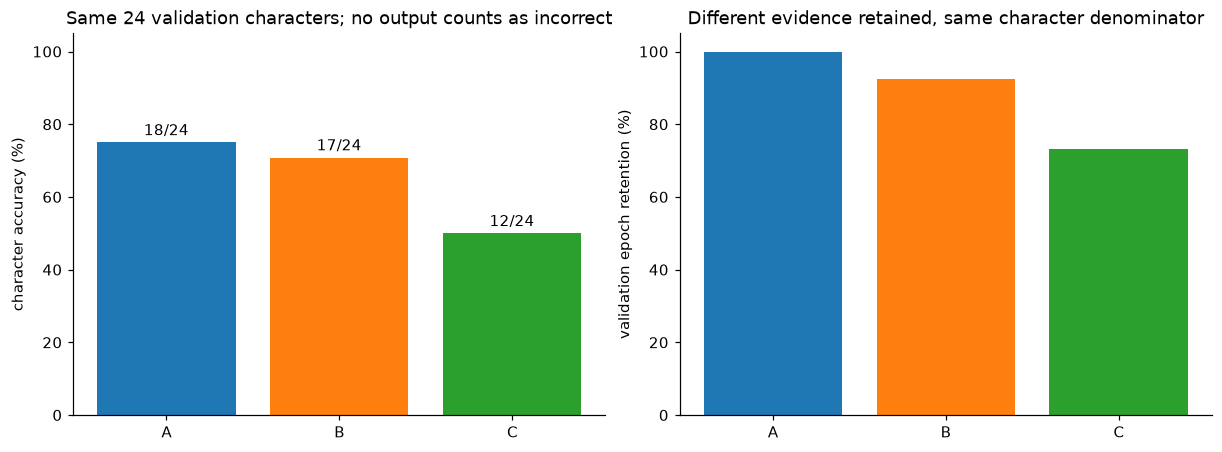

In [9]:
display(overall)
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].bar(overall.policy,overall.character_accuracy*100,color=['tab:blue','tab:orange','tab:green'])
axes[0].set(ylim=(0,105),ylabel='character accuracy (%)',title='Same 24 validation characters; no output counts as incorrect')
for i,row in enumerate(overall.itertuples()):axes[0].text(i,row.character_accuracy*100+2,f'{row.correct_characters}/{row.validation_characters}',ha='center')
axes[1].bar(pooled.index,pooled.retention*100,color=['tab:blue','tab:orange','tab:green'])
axes[1].set(ylim=(0,105),ylabel='validation epoch retention (%)',title='Different evidence retained, same character denominator')
fig.savefig(OUT/'accuracy_and_retention.png',dpi=120);plt.show()


## 9. 被试与Session：不能只看总体

F05在A下8/8、B下7/8、C下2/8，C有4个无输出；F20在C下由3/4变为4/4。F06与F25基础表现较低，不能由F03/F05的高结果掩盖。

这些差异可能涉及信号质量、非平稳性、类别相关伪迹和证据损失等，当前实验不能判定具体来源。候选剔除改变准确率也不能证明保留下来的特征一定是纯P300。


In [10]:
subject=pd.read_csv(OUT/'subject_character_summary.csv')
display(subject)
display(pd.read_csv(OUT/'session_character_summary.csv'))
# The combined subject error-bar figure is shown in section 14.


,policy,subject_id,validation_characters,correct_characters,character_accuracy,output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,mean_valid_flashes,no_output_characters
0,A,F_03,4,4,1.000,4,0.00000,0.00000,126.000,0
1,A,F_05,8,8,1.000,8,0.00000,0.00000,126.000,0
2,A,F_06,4,1,0.250,4,0.00000,0.00000,126.000,0
3,A,F_08,2,2,1.000,2,0.00000,0.00000,126.000,0
4,A,F_20,4,3,0.750,4,0.00000,0.00000,126.000,0
5,A,F_25,2,0,0.000,2,0.00000,0.00000,126.000,0
6,B,F_03,4,4,1.000,4,0.00000,0.00000,126.000,0
7,B,F_05,8,7,0.875,8,0.00000,0.00000,101.000,0
8,B,F_06,4,1,0.250,4,0.00000,0.00000,124.500,0
9,B,F_08,2,2,1.000,2,0.00000,0.00000,115.500,0


,policy,subject_id,session_id,validation_characters,correct_characters,character_accuracy,output_characters,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,mean_valid_flashes,no_output_characters
0,A,F_03,SE001,2,2,1.00,2,0.00000,0.00000,126.00,0
1,A,F_03,SE002,2,2,1.00,2,0.00000,0.00000,126.00,0
2,A,F_05,SE001,2,2,1.00,2,0.00000,0.00000,126.00,0
3,A,F_05,SE002,4,4,1.00,4,0.00000,0.00000,126.00,0
4,A,F_05,SE003,2,2,1.00,2,0.00000,0.00000,126.00,0
5,A,F_06,SE001,2,0,0.00,2,0.00000,0.00000,126.00,0
6,A,F_06,SE002,2,1,0.50,2,0.00000,0.00000,126.00,0
7,A,F_08,SE003,2,2,1.00,2,0.00000,0.00000,126.00,0
8,A,F_20,SE001,2,2,1.00,2,0.00000,0.00000,126.00,0
9,A,F_20,SE002,2,1,0.50,2,0.00000,0.00000,126.00,0


## 10. 配对比较与小样本限制

A→B没有新增正确字符、损失1个；A→C新增正确1个、损失7个。表内精确配对binomial检验只描述不一致字符，样本很小，没有做策略再调参或据p值确定最终方案。

当前不能说差异已形成可靠总体规律；也不能因C总体下降就说所有眨眼处理都无效。该结论严格限定旧区间版本与当前完整字符末端评分。


In [11]:
display(pd.read_csv(OUT/'paired_strategy_summary.csv'))
paired=pd.read_csv(OUT/'paired_character_comparison.csv')
display(paired[['edf_name','character_key','true_character','predicted_character_A','predicted_character_B','predicted_character_C','correct_A','correct_B','correct_C','valid_flashes_A','valid_flashes_B','valid_flashes_C']])


,first,second,characters,second_only_correct,first_only_correct,accuracy_difference,paired_exact_binomial_p,mean_extra_wait_seconds,note
0,A,B,24,0,1,-0.041667,1.000000,0.00000,descriptive paired development comparison; no ...
1,A,C,24,1,7,-0.250000,0.070312,1.34375,descriptive paired development comparison; no ...
2,B,C,24,1,6,-0.208333,0.125000,1.34375,descriptive paired development comparison; no ...


,edf_name,character_key,true_character,predicted_character_A,predicted_character_B,predicted_character_C,correct_A,correct_B,correct_C,valid_flashes_A,valid_flashes_B,valid_flashes_C
0,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T05,R_3_6,R_3_6,R_3_6,R_3_6,True,True,True,126,126,126
1,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_T06,E_1_5,E_1_5,E_1_5,E_1_5,True,True,True,126,126,126
2,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_T05,N_3_2,N_3_2,N_3_2,N_3_2,True,True,True,126,126,126
3,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_T06,G_2_1,G_2_1,G_2_1,A_1_1,True,True,False,126,126,126
4,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_T05,I_2_3,I_2_3,I_2_3,I_2_3,True,True,True,126,123,79
5,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_T06,T_4_2,T_4_2,T_4_2,H_2_2,True,True,False,126,124,57
6,F_05_SE002_CBCol_Train02.edf,F_05_SE002_CBCol_Train02_T03,D_1_4,D_1_4,D_1_4,NaN,True,True,False,126,83,36
7,F_05_SE002_CBCol_Train02.edf,F_05_SE002_CBCol_Train02_T04,D_1_4,D_1_4,D_1_4,NaN,True,True,False,126,84,40
8,F_05_SE002_CBCol_Train02.edf,F_05_SE002_CBCol_Train02_T05,L_2_6,L_2_6,L_2_6,L_2_6,True,True,True,126,85,60
9,F_05_SE002_CBCol_Train02.edf,F_05_SE002_CBCol_Train02_T06,E_1_5,E_1_5,F_1_6,NaN,True,False,False,126,58,19


## 11. Epoch ROC-AUC：各自有效与共同有效要分开

own_valid_scored_epochs使用各模型自己保留的验证epoch，评价对象不同；common_valid_scored_epochs_A_B_C只用同一被试×Session中三组共同有分数的验证事件，三组样本相同。

总体仅报告11个模型组AUC的宏平均，不把不同模型未校准分数直接拼起来算一个ROC。AUC为辅助指标，不代替字符准确率或无输出率。


,model_id,policy,subject_id,session_id,site,scope,n_epochs,auc
0,F_03_SE001,A,F_03,SE001,ETSU,own_valid_scored_epochs,252,0.800064
1,F_03_SE001,B,F_03,SE001,ETSU,own_valid_scored_epochs,252,0.800064
2,F_03_SE001,C,F_03,SE001,ETSU,own_valid_scored_epochs,252,0.800064
3,F_03_SE001,A,F_03,SE001,ETSU,common_valid_scored_epochs_A_B_C,252,0.800064
4,F_03_SE001,B,F_03,SE001,ETSU,common_valid_scored_epochs_A_B_C,252,0.800064
...,...,...,...,...,...,...,...,...
61,F_25_SE001,B,F_25,SE001,ETSU,own_valid_scored_epochs,252,0.649713
62,F_25_SE001,C,F_25,SE001,ETSU,own_valid_scored_epochs,154,0.699760
63,F_25_SE001,A,F_25,SE001,ETSU,common_valid_scored_epochs_A_B_C,154,0.544844
64,F_25_SE001,B,F_25,SE001,ETSU,common_valid_scored_epochs_A_B_C,154,0.652758


,policy,scope,model_folds,macro_auc
0,A,common_valid_scored_epochs_A_B_C,11,0.773763
1,A,own_valid_scored_epochs,11,0.784819
2,B,common_valid_scored_epochs_A_B_C,11,0.765207
3,B,own_valid_scored_epochs,11,0.781899
4,C,common_valid_scored_epochs_A_B_C,11,0.729259
5,C,own_valid_scored_epochs,11,0.766166


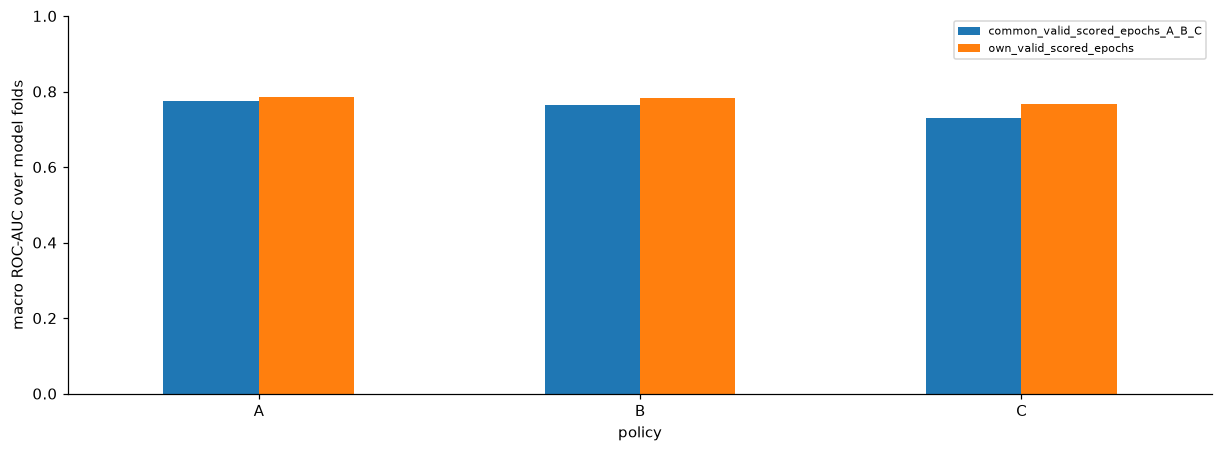

In [12]:
display(auc)
macro=pd.read_csv(OUT/'overall_macro_auc.csv')
display(macro)
fig,ax=plt.subplots(figsize=(11,4),layout='constrained')
macro.pivot(index='policy',columns='scope',values='macro_auc').plot.bar(ax=ax,rot=0)
ax.set(ylim=(0,1),ylabel='macro ROC-AUC over model folds');ax.legend(fontsize=7)
fig.savefig(OUT/'auxiliary_auc.png',dpi=120);plt.show()


## 12. 实际可用时间：按记录时间戳取最大，不逐flash相加

epoch使用256Hz下205点，等待完整800ms数据；现有样本端点约定使表中数据就绪时刻最多多0.781ms。C还使用旧区间策略的统一保守确认窗口，约1.355秒，用于确定“没有稍后确认的候选会重叠”。

字符证据就绪时刻为max(SelectedTarget字符结束边界、该字符全部flash的policy_decision_seconds)，不把各flash等待逐个相加。本轮A/B在记录的字符结束时刻已具备数据；C平均再等1.34375秒（字符结束边界已经覆盖了一小段epoch等待）。

evidence_ready_seconds始终记录完成此次判定的样本时钟；无输出时prediction_available_seconds留空。时间是数据回放模拟，不包含未测量的设备通信和逐epoch计算时延；CPU训练耗时另存，不能冒称实机端到端延迟。


,policy,edf_name,character_trial_id,output_available,last_flash_seconds,trial_end_seconds,evidence_ready_seconds,prediction_available_seconds,decision_latency_after_trial_end_seconds
0,A,F_03_SE001_CBCol_Train01.edf,5,True,175.75,176.5625,176.56250,176.56250,0.00000
1,A,F_03_SE001_CBCol_Train01.edf,6,True,210.75,211.5625,211.56250,211.56250,0.00000
2,B,F_03_SE001_CBCol_Train01.edf,5,True,175.75,176.5625,176.56250,176.56250,0.00000
3,B,F_03_SE001_CBCol_Train01.edf,6,True,210.75,211.5625,211.56250,211.56250,0.00000
4,C,F_03_SE001_CBCol_Train01.edf,5,True,175.75,176.5625,177.90625,177.90625,1.34375
5,C,F_03_SE001_CBCol_Train01.edf,6,True,210.75,211.5625,212.90625,212.90625,1.34375
6,A,F_03_SE002_CBCol_Train01.edf,5,True,175.75,176.5625,176.56250,176.56250,0.00000
7,A,F_03_SE002_CBCol_Train01.edf,6,True,210.75,211.5625,211.56250,211.56250,0.00000
8,B,F_03_SE002_CBCol_Train01.edf,5,True,175.75,176.5625,176.56250,176.56250,0.00000
9,B,F_03_SE002_CBCol_Train01.edf,6,True,210.75,211.5625,211.56250,211.56250,0.00000


,policy,mean_decision_wait_after_trial_seconds,mean_output_wait_after_trial_seconds,no_output_characters
0,A,0.00000,0.00000,0
1,B,0.00000,0.00000,0
2,C,1.34375,1.34375,4


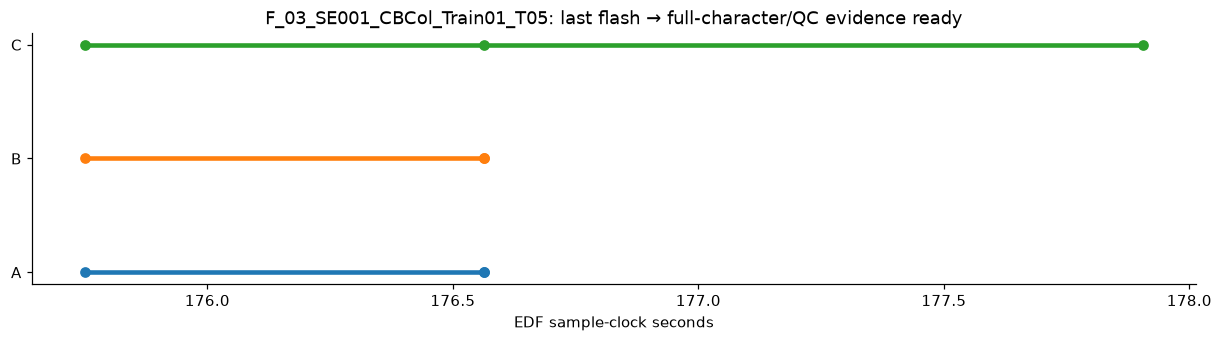

In [13]:
display(pred[['policy','edf_name','character_trial_id','output_available','last_flash_seconds','trial_end_seconds','evidence_ready_seconds','prediction_available_seconds','decision_latency_after_trial_end_seconds']].head(12))
display(overall[['policy','mean_decision_wait_after_trial_seconds','mean_output_wait_after_trial_seconds','no_output_characters']])
key=pred.character_key.iloc[0]
t=pred[pred.character_key.eq(key)].set_index('policy')
fig,ax=plt.subplots(figsize=(11,3),layout='constrained')
for i,policy in enumerate(['A','B','C']):
    row=t.loc[policy]
    ax.plot([row.last_flash_seconds,row.evidence_ready_seconds],[i,i],lw=3)
    ax.scatter([row.last_flash_seconds,row.trial_end_seconds,row.evidence_ready_seconds],[i,i,i],marker='o')
ax.set(yticks=[0,1,2],yticklabels=['A','B','C'],xlabel='EDF sample-clock seconds',title=f'{key}: last flash → full-character/QC evidence ready')
fig.savefig(OUT/'one_character_timing.png',dpi=120);plt.show()


## 13. 本轮结论与复现

在当前开发划分中：PTP150µV没有提高字符准确率，少了1个正确字符；旧眨眼区间拒绝总体下降，并增加无输出和约1.34秒的确认等待，收益没有抵消本轮证据损失。但F20有个别改善，样本24个字符也很少，因此不据此继续修改检测参数或断言普遍结论。

复现：`scripts/run_swlda_rejection_experiment.py`；固定配置：`configs/swlda_rejection_experiment.json`。保存划分、输入hash、映射、特征、33个模型、选中特征与步骤、逐epoch分数、逐字符预测、刺激集合/字符有效flash数、AUC与配对比较。

39项单元检查通过，包含SWLDA与独立直接OLS逐步参考的一致性、共线特征处理、整数采样窗、拒绝flash为缺失而非0、证据次数归一化及AUC。另核验33个模型的均值/标准差确实来自各自训练保留集，最终特征显著性和保存分数一致。

既有预处理开发与人工复核曾使用这些Train记录，且4份补充文件因有标注而选入；这不是独立最终测试。最终Test没有读取，策略也未自动启用或部署。


In [14]:
scores=pd.read_csv(OUT/'epoch_scores.csv',usecols=['policy','set','would_keep','target_score','has_score','character_key'])
assert scores.loc[~scores.would_keep,'target_score'].isna().all()
assert not scores.loc[~scores.would_keep,'has_score'].any()
assert pred.groupby('policy').size().eq(24).all()
assert pred.groupby('character_key').policy.nunique().eq(3).all()
assert pred.loc[~pred.output_available,'prediction_available_seconds'].isna().all()
assert not pred.loc[~pred.output_available,'correct'].any()
assert models.shape[0]==33 and models.fit_status.eq('converged').all()
assert models.n_selected.le(60).all()
assert record['feature_selection_training_only'] and not record['ordinary_or_regularized_lda_substitution']
assert not record['used_final_test_data']
assert config['blink_interval_version']=='old_candidate_overlap_v1'
print('PASS: same 24 validation characters, missing rejected scores, fixed C version, true train-only SWLDA, no final Test data')


PASS: same 24 validation characters, missing rejected scores, fixed C version, true train-only SWLDA, no final Test data


## 14. 每位被试的独立模型结果

六位被试合并为一张误差线图，左右分别展示字符准确率和验证epoch保留率。点为该被试各Session的等权均值，误差线为Session间样本标准差（±1 SD），不是置信区间；只有一个Session时仅显示点，标准差记为缺失。均值±SD可能超出0–100%，不截短误差线。此图的Session等权均值与下方按字符数汇总的准确率可能不同，尤其F05各Session验证字符数量不同。

以下按被试分别展示A/B/C，不重新训练或改变划分。模型按“被试×Session”独立训练；同一被试多个Session的结果汇总展示，不表示拟合了跨Session合并模型。

每个人依次展示：字符准确率、无输出数、epoch保留率和确认等待；各Session模型的训练预算、选中特征数与验证AUC；逐字符真值、预测及有效flash数。无输出计为错误。AUC在各Session分别计算，不拼接不同模型的分数。每Session仅有2–4个验证字符，不应将结果高低视为稳定个体差异。

数值另存为subject_model_results.csv和subject_session_model_results.csv。所选特征与权重见models目录下对应model_id和策略的文件。


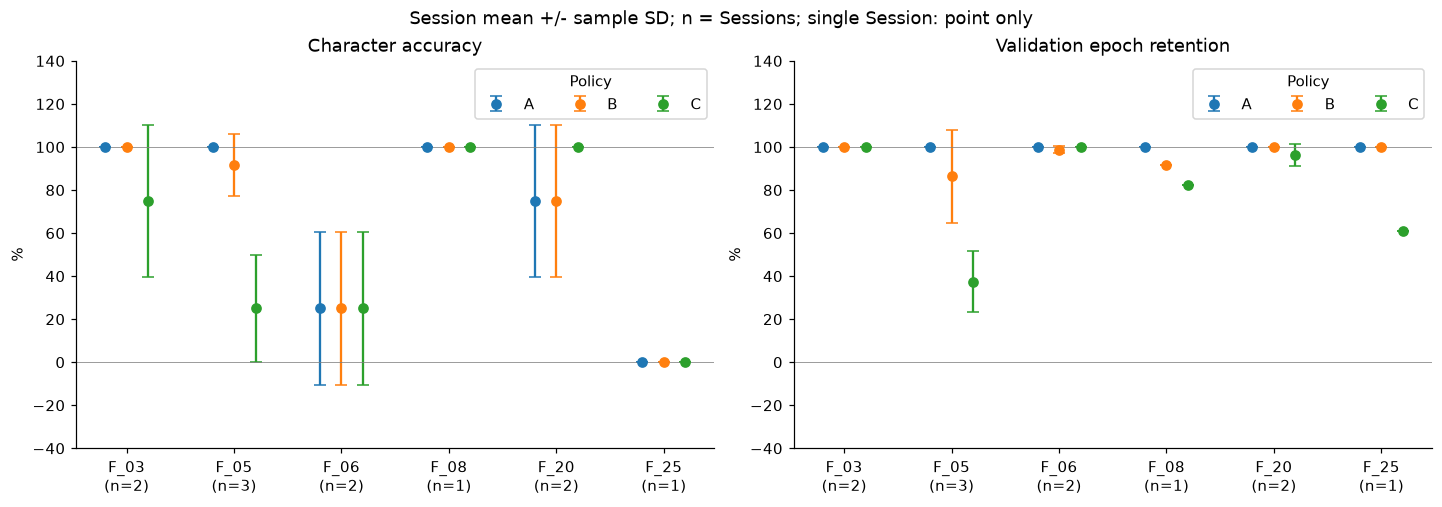

### F_03

,policy,correct_characters,validation_characters,character_accuracy,no_output_characters,kept,collected,epoch_retention,mean_decision_wait_after_trial_seconds
0,A,4,4,1.00,0,504,504,1.0,0.0000
6,B,4,4,1.00,0,504,504,1.0,0.0000
12,C,3,4,0.75,0,504,504,1.0,1.3438


**各Session独立模型**：own_auc与common_auc分别对应各自有效epoch和三策略共同有效epoch。

,model_id,policy,training_characters,training_epochs,n_selected,fit_status,correct_characters,validation_characters,no_output_characters,retention,own_auc,common_auc
0,F_03_SE001,A,4,482,34,converged,2,2,0,1.0,0.8001,0.8001
1,F_03_SE001,B,4,482,34,converged,2,2,0,1.0,0.8001,0.8001
2,F_03_SE001,C,4,482,34,converged,2,2,0,1.0,0.8001,0.8001
3,F_03_SE002,A,4,482,25,converged,2,2,0,1.0,0.6725,0.6725
4,F_03_SE002,B,4,482,25,converged,2,2,0,1.0,0.6725,0.6725
5,F_03_SE002,C,4,471,24,converged,1,2,0,1.0,0.6344,0.6344


**逐字符结果**：predicted_character为空表示无输出；相同character_key对应三策略评价的同一个验证字符。

,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,prediction_status,correct,valid_flashes,collected_flashes,decision_latency_after_trial_end_seconds
0,SE001,F_03_SE001_CBCol_Train01.edf,5,A,R_3_6,R_3_6,predicted,True,126,126,0.00000
2,SE001,F_03_SE001_CBCol_Train01.edf,5,B,R_3_6,R_3_6,predicted,True,126,126,0.00000
4,SE001,F_03_SE001_CBCol_Train01.edf,5,C,R_3_6,R_3_6,predicted,True,126,126,1.34375
1,SE001,F_03_SE001_CBCol_Train01.edf,6,A,E_1_5,E_1_5,predicted,True,126,126,0.00000
3,SE001,F_03_SE001_CBCol_Train01.edf,6,B,E_1_5,E_1_5,predicted,True,126,126,0.00000
5,SE001,F_03_SE001_CBCol_Train01.edf,6,C,E_1_5,E_1_5,predicted,True,126,126,1.34375
6,SE002,F_03_SE002_CBCol_Train01.edf,5,A,N_3_2,N_3_2,predicted,True,126,126,0.00000
8,SE002,F_03_SE002_CBCol_Train01.edf,5,B,N_3_2,N_3_2,predicted,True,126,126,0.00000
10,SE002,F_03_SE002_CBCol_Train01.edf,5,C,N_3_2,N_3_2,predicted,True,126,126,1.34375
7,SE002,F_03_SE002_CBCol_Train01.edf,6,A,G_2_1,G_2_1,predicted,True,126,126,0.00000


... (27 outputs left out)

,model_id,policy,training_characters,training_epochs,n_selected,fit_status,correct_characters,validation_characters,no_output_characters,retention,own_auc,common_auc
30,F_25_SE001,A,4,482,32,converged,0,2,0,1.0000,0.5810,0.5448
31,F_25_SE001,B,4,479,28,converged,0,2,0,1.0000,0.6497,0.6528
32,F_25_SE001,C,4,350,20,converged,0,2,0,0.6111,0.6998,0.6998


**逐字符结果**：predicted_character为空表示无输出；相同character_key对应三策略评价的同一个验证字符。

,session_id,edf_name,character_trial_id,policy,true_character,predicted_character,prediction_status,correct,valid_flashes,collected_flashes,decision_latency_after_trial_end_seconds
66,SE001,F_25_SE001_CBCol_Train01.edf,5,A,N_3_2,Z_5_2,predicted,False,126,126,0.00000
68,SE001,F_25_SE001_CBCol_Train01.edf,5,B,N_3_2,E_1_5,predicted,False,126,126,0.00000
70,SE001,F_25_SE001_CBCol_Train01.edf,5,C,N_3_2,X_4_6,predicted,False,93,126,1.34375
67,SE001,F_25_SE001_CBCol_Train01.edf,6,A,T_4_2,F_1_6,predicted,False,126,126,0.00000
69,SE001,F_25_SE001_CBCol_Train01.edf,6,B,T_4_2,F_1_6,predicted,False,126,126,0.00000
71,SE001,F_25_SE001_CBCol_Train01.edf,6,C,T_4_2,8_6_5,predicted,False,61,126,1.34375


PASS: individual tables reconcile with all 33 models and the overall 24-character comparison


In [15]:
from IPython.display import Markdown
subject_results=pd.read_csv(OUT/'subject_character_summary.csv')
retention=pd.read_csv(OUT/'validation_retention.csv')
subject_retention=retention.groupby(['subject_id','policy'],as_index=False)[['collected','kept']].sum()
subject_retention['epoch_retention']=subject_retention.kept/subject_retention.collected
subject_results=subject_results.merge(subject_retention,on=['subject_id','policy'],validate='one_to_one')
subject_results.to_csv(OUT/'subject_model_results.csv',index=False)
session_results=models.merge(pd.read_csv(OUT/'session_character_summary.csv'),on=['policy','subject_id','session_id','validation_characters'],validate='one_to_one')
session_results=session_results.merge(retention,on=['policy','subject_id','session_id'],validate='one_to_one')
for scope,label in [('own_valid_scored_epochs','own_auc'),('common_valid_scored_epochs_A_B_C','common_auc')]:
    session_results=session_results.merge(auc.loc[auc.scope.eq(scope),['model_id','policy','auc']].rename(columns={'auc':label}),on=['model_id','policy'],validate='one_to_one')
session_results.to_csv(OUT/'subject_session_model_results.csv',index=False)
# Session is the replicate; SD is undefined for a single Session.
subjects=sorted(subject_results.subject_id.unique())
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
error_rows=[]
for ax,metric,title in zip(axes,['character_accuracy','retention'],['Character accuracy','Validation epoch retention']):
    for j,policy in enumerate(['A','B','C']):
        stats=session_results.loc[session_results.policy.eq(policy)].groupby('subject_id')[metric].agg(['mean','std','count']).reindex(subjects)
        x=np.arange(len(subjects))+(j-1)*0.2
        ax.errorbar(x,stats['mean']*100,yerr=stats['std'].fillna(0)*100,fmt='o',capsize=4,label=policy,color=['tab:blue','tab:orange','tab:green'][j])
        for subject,row in stats.iterrows():
            error_rows.append(dict(subject_id=subject,policy=policy,metric=metric,session_mean=row['mean'],session_sd=row['std'],n_sessions=int(row['count'])))
    ax.set(xticks=np.arange(len(subjects)),xticklabels=[f'{sub}\n(n={session_results.loc[session_results.subject_id.eq(sub),"session_id"].nunique()})' for sub in subjects],ylabel='%',title=title,ylim=(-40,140))
    ax.axhline(0,color='grey',lw=.5);ax.axhline(100,color='grey',lw=.5)
    ax.legend(title='Policy',ncol=3)
fig.suptitle('Session mean +/- sample SD; n = Sessions; single Session: point only')
fig.savefig(OUT/'subject_model_errorbars.png',dpi=150)
plt.show()
pd.DataFrame(error_rows).to_csv(OUT/'subject_model_errorbars.csv',index=False)
for subject in sorted(subject_results.subject_id.unique()):
    display(Markdown(f'### {subject}'))
    sub=subject_results.loc[subject_results.subject_id.eq(subject)].sort_values('policy')
    display(sub[['policy','correct_characters','validation_characters','character_accuracy','no_output_characters','kept','collected','epoch_retention','mean_decision_wait_after_trial_seconds']].round(4))

    display(Markdown('**各Session独立模型**：own_auc与common_auc分别对应各自有效epoch和三策略共同有效epoch。'))
    rows=session_results.loc[session_results.subject_id.eq(subject)].sort_values(['session_id','policy'])
    display(rows[['model_id','policy','training_characters','training_epochs','n_selected','fit_status','correct_characters','validation_characters','no_output_characters','retention','own_auc','common_auc']].round(4))
    display(Markdown('**逐字符结果**：predicted_character为空表示无输出；相同character_key对应三策略评价的同一个验证字符。'))
    display(pred.loc[pred.subject_id.eq(subject),['session_id','edf_name','character_trial_id','policy','true_character','predicted_character','prediction_status','correct','valid_flashes','collected_flashes','decision_latency_after_trial_end_seconds']].sort_values(['session_id','edf_name','character_trial_id','policy']))
assert len(session_results)==33
assert subject_results.groupby('policy').validation_characters.sum().eq(24).all()
assert subject_results.groupby('policy').correct_characters.sum().to_dict()==overall.set_index('policy').correct_characters.to_dict()
print('PASS: individual tables reconcile with all 33 models and the overall 24-character comparison')
